<a href="https://colab.research.google.com/github/debashisdotchatterjee/CHMMOTv1-Clinical-Data-ML-Paper1-v2/blob/main/CHMMOT_JOINT_COMPLETE_COLAB_Revised_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CHMMOTv1 | Complete  joint-methodology revised code

**Scientific aim:** Preserve and genuinely fit the original shared-representation, two-organ cumulative-link ordinal model, exact MRI monotonicity, fused within-training-patient effects and split conformal uncertainty. **Do not replace the proposed model with separate XGBoost classifiers**; those appear only as comparison arms and to reproduce all previous reviewer-requested figures/tables.

### Core equations

$$
\eta_{it}^{(m)}=\beta_m^\top W^\top u_{it}+s_m a_m v_{it}^{(m)}+\delta_{it}^{(m)},\qquad
P(Y_{it}^{(m)}\le k)=\sigma(\tau_k^{(m)}-\eta_{it}^{(m)}).
$$

$W$ is shared across cardiac and hepatic tasks. $u$ contains nonredundant clinical features; $v$ is own-organ MRI; $a_m>0$ enforces correct MRI monotonicity with $s_m=-1$ for $T2^*$ (and positive for $R2^*$ or iron-concentration variants). Thresholds are strictly ordered by construction. Training-subject offsets receive L2 anchoring and total-variation penalties across **workbook-listed records**; the penalized predictor also receives a small TV term. There are no visit dates. Unseen patients have $\delta=0$. The estimation routine uses Adam subgradient optimization.

### Scientific safeguards

* Split by **patient** across training, tuning, calibration, and test. Training+tuning are refit before evaluation; calibration/test patients are held out.
* Primary evaluation: **first listed encounter per patient**, not all correlated records treated as independent.
* **Joint conformal prediction** in addition to separate organwise coverage, using calibration score $\max_m(1-\widehat p_m(Y^{(m)}))$.
* Compare full joint + monotonicity + fusion against loss of any component, independent ordinal models, MRI-only and tree baselines.
* Do not claim successful external validation or benefits unsupported by the ablations.

Run all cells below. The results ZIP is generated and downloaded automatically; figures also appear inline for inspection.


In [1]:
!pip -q install "numpy>=1.26" "pandas>=2.1" "scipy>=1.11" "matplotlib>=3.7" "scikit-learn>=1.3" "xgboost>=2.0" "openpyxl>=3.1"
import torch
print("PyTorch", torch.__version__)

PyTorch 2.11.0+cpu


## Included reference pipeline (comparators and original analysis figures)
All source code is carried inside this notebook. Nothing has to be fetched from GitHub.

In [2]:
%%writefile reference_xgboost_pipeline.py
# %%
"""
PLOS ONE PONE-D-25-66355 | Patient-grouped, reproducible ordinal MRI analysis
===============================================================================
Primary estimand: performance for the FIRST LISTED record of a NEW patient.
Development models can use all listed visits of training patients, weighted so
that each training patient has total sample weight 1. No visit dates are given.

Run in Google Colab, or: python CHMMOT_PLOS_revision_pipeline.py --input FILE.xlsx
Figures: 300 dpi PNG and vector PDF. Tables: CSV + LaTeX; diagnostic logs: JSON.
No new patient labels or clinical thresholds are invented; questionable records
are flagged, not silently corrected or removed from the primary analysis.

Caveats: the five-class outcomes are the provided source labels, not externally
adjudicated SCMR stages; labels may be derived from MRI values. This code does
NOT fit a joint multitask longitudinal model, claim external validation, or
establish clinical utility beyond the study cohort.
"""

# %%
import argparse
import csv
import hashlib
import json
import logging
import math
import os
import platform
import re
import sys
import warnings
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import beta, spearmanr
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, cohen_kappa_score,
                             mean_absolute_error, precision_recall_fscore_support)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import sklearn

SEED = 20261026
LABELS = ('Normal', 'Mild', 'Moderate', 'Severe', 'Very Severe')
CLASSES = np.arange(5, dtype=int)
DATA_COLS = ["Patient Code", "Age", "Sex", "T2*(Cardiac)", "R2*(Cardiac)",
             "MIC", "Cardiac Overload", "T2*(Liver)", "R2*(Liver)", "LIC",
             "Liver Overload", "Ferritin", "AST", "ALT", "ALP", "BILL D", "BILL T"]
NUMERIC = [c for c in DATA_COLS if c not in ('Patient Code', 'Sex', 'Cardiac Overload', 'Liver Overload')]
CLINICAL = ['Age', 'Sex_binary', 'Ferritin_log1p', 'AST', 'ALT', 'ALP', 'BILL D', 'BILL T']
ORGANS = {'Cardiac': {'label': 'Cardiac Overload', 't2': 'T2*(Cardiac)', 'r2': 'R2*(Cardiac)', 'derived': 'MIC'},
          'Hepatic': {'label': 'Liver Overload', 't2': 'T2*(Liver)', 'r2': 'R2*(Liver)', 'derived': 'LIC'}}
PAPER_COLORS = {'navy':'#1B2C45','teal':'#0E827E','coral':'#C15B51', 'gold':'#D9A44D',
                'pale':'#F1F5F8','gray':'#6E7886', 'violet':'#7773B6'}
COLORS = [PAPER_COLORS['navy'], PAPER_COLORS['teal'], PAPER_COLORS['gold'], PAPER_COLORS['coral'], PAPER_COLORS['violet']]
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10,'axes.titlesize':12,
                     'axes.labelsize':10,'axes.spines.top':False,'axes.spines.right':False,
                     'axes.labelcolor':PAPER_COLORS['navy'],'text.color':PAPER_COLORS['navy'],
                     'axes.edgecolor':'#8D98A6','xtick.color':'#4A5564','ytick.color':'#4A5564',
                     'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white',
                     'grid.color':'#E3E9ED','grid.linewidth':.7})

# %%
def safe_json(obj):
    if isinstance(obj,(np.integer,)): return int(obj)
    if isinstance(obj,(np.floating,)): return None if not np.isfinite(obj) else float(obj)
    if isinstance(obj,np.ndarray): return obj.tolist()
    if isinstance(obj,Path): return str(obj)
    if isinstance(obj,(pd.Timestamp,datetime)): return str(obj)
    if isinstance(obj,float) and not np.isfinite(obj): return None
    raise TypeError(f'Unsupported JSON type {type(obj)}')


def write_json(path, obj):
    Path(path).write_text(json.dumps(obj,indent=2,default=safe_json,allow_nan=False),encoding='utf-8')


def export_table(out, stem, df, index=False):
    dest = out/'tables'
    dest.mkdir(parents=True,exist_ok=True)
    df.to_csv(dest/f'{stem}.csv', index=index, na_rep='NA')
    def fmt(v):
        if pd.isna(v):return '--'
        if isinstance(v,(float,np.floating)) and not np.isfinite(v): return '--'
        return str(v)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        try:
            (dest/f'{stem}.tex').write_text(df.to_latex(index=index,escape=True,
                na_rep='--',float_format=lambda x:f'{x:.4f}'),encoding='utf-8')
        except Exception as e: logging.warning('LaTeX table export %s: %s',stem,e)


def export_fig(out, stem, fig):
    (out/'figures').mkdir(parents=True,exist_ok=True)
    fig.savefig(out/'figures'/f'{stem}.png', dpi=300, bbox_inches='tight',pad_inches=.12)
    fig.savefig(out/'figures'/f'{stem}.pdf', bbox_inches='tight',pad_inches=.12)
    plt.close(fig)


def style_ax(ax, title='', xlabel='', ylabel=''):
    ax.set_title(title,loc='left',fontweight='bold',pad=12)
    ax.set_xlabel(xlabel);ax.set_ylabel(ylabel)
    ax.grid(axis='y',alpha=.8);ax.set_axisbelow(True)


def norm_label(v):
    if pd.isna(v):return None
    s=' '.join(str(v).strip().casefold().split())
    d={lab.casefold():i for i,lab in enumerate(LABELS)}
    return d.get(s,None)


def load_audit_workbook(path,out):
    xls=pd.ExcelFile(path)
    expected={'With Follow-Up','Without Follow-Up'}
    if not expected.issubset(xls.sheet_names):
        raise ValueError(f'Workbook needs sheets {expected}; found {xls.sheet_names}')
    parts=[]
    for sheet in ('With Follow-Up','Without Follow-Up'):
        z=pd.read_excel(xls,sheet_name=sheet)
        if not set(DATA_COLS).issubset(z.columns):
            raise ValueError(f'Missing columns on {sheet}: {set(DATA_COLS)-set(z.columns)}')
        z=z[DATA_COLS].copy();z['source_sheet']=sheet
        z['excel_row']=np.arange(2,len(z)+2)
        parts.append(z)
    d=pd.concat(parts,ignore_index=True)
    d['patient_id']=d['Patient Code'].astype('string').str.strip()
    if d.patient_id.isna().any() or (d.patient_id=='').any():
        raise ValueError('Missing patient IDs. Must resolve before patient-grouped analysis.')
    if d.duplicated(subset=['patient_id','source_sheet','excel_row']).any():
        raise ValueError('Duplicate row keys.')
    for col in NUMERIC:
        d[col]=pd.to_numeric(d[col],errors='coerce')
    d['Sex_binary']=d['Sex'].astype('string').str.upper().str.strip().map({'F':0,'M':1}).astype(float)
    d['Ferritin_log1p']=np.log1p(d['Ferritin'].clip(lower=0))
    d['y_Cardiac']=d['Cardiac Overload'].map(norm_label)
    d['y_Hepatic']=d['Liver Overload'].map(norm_label)
    if d[['y_Cardiac','y_Hepatic']].isna().any().any():
        bad=d[d[['y_Cardiac','y_Hepatic']].isna().any(axis=1)][['source_sheet','excel_row','Cardiac Overload','Liver Overload']]
        export_table(out,'audit_unrecognized_labels',bad)
        raise ValueError('Unknown outcome labels. See audit_unrecognized_labels.csv')
    d[['y_Cardiac','y_Hepatic']]=d[['y_Cardiac','y_Hepatic']].astype(int)
    # Row index is the ONLY visit-order surrogate. Never interpret as time.
    d['listed_visit_order']=d.groupby('patient_id',sort=False).cumcount()+1
    d['n_listed_visits']=d.groupby('patient_id')['patient_id'].transform('size')
    d['is_first_listed']=d['listed_visit_order'].eq(1)
    d['reciprocal_Cardiac']=d['T2*(Cardiac)']*d['R2*(Cardiac)']/1000
    d['reciprocal_Hepatic']=d['T2*(Liver)']*d['R2*(Liver)']/1000
    for organ in ORGANS:
        t=d[ORGANS[organ]['t2']];r=d[ORGANS[organ]['r2']]
        bad=(t<=0)|(r<=0)|((d['reciprocal_'+organ]-1).abs()>.15)
        d[f'flag_reciprocity_{organ}']=bad.fillna(True)
    d['flag_any_reciprocity']=d['flag_reciprocity_Cardiac']|d['flag_reciprocity_Hepatic']
    d['flag_invalid_measurement']=False
    for col in ('T2*(Cardiac)','R2*(Cardiac)','T2*(Liver)','R2*(Liver)','LIC','MIC'):
        d['flag_invalid_measurement']|=(d[col]<=0).fillna(False)
    # Multiple visits with exactly identical MRI but different label: not auto-fixed.
    d['flag_label_disagreement_identical_mri']=False
    for organ in ORGANS:
        f=ORGANS[organ]
        by=d.groupby(['patient_id',f['t2'],f['r2']],dropna=False)['y_'+organ].transform('nunique')>1
        d['flag_label_disagreement_identical_mri']|=by
    inventory=pd.DataFrame([
        {'Quantity':'Workbook sheets','Value':', '.join(xls.sheet_names)},
        {'Quantity':'Total listed records','Value':len(d)},
        {'Quantity':'Distinct patient identifiers','Value':d.patient_id.nunique()},
        {'Quantity':'Follow-up-sheet patients','Value':d.loc[d.source_sheet=='With Follow-Up','patient_id'].nunique()},
        {'Quantity':'No-follow-up-sheet patients','Value':d.loc[d.source_sheet=='Without Follow-Up','patient_id'].nunique()},
        {'Quantity':'Patients appearing in both sheets','Value':len(set(parts[0]['Patient Code'])&set(parts[1]['Patient Code']))},
        {'Quantity':'Repeated-record patients','Value':int((d.groupby('patient_id').size()>1).sum())},
        {'Quantity':'Rows with >15% cardiac T2*/R2* reciprocal deviation','Value':int(d.flag_reciprocity_Cardiac.sum())},
        {'Quantity':'Rows with >15% hepatic T2*/R2* reciprocal deviation','Value':int(d.flag_reciprocity_Hepatic.sum())},
        {'Quantity':'Rows with identical MRI measurements but discordant label for same patient','Value':int(d.flag_label_disagreement_identical_mri.sum())},
        {'Quantity':'Records with at least one NA in input columns','Value':int(d[DATA_COLS].isna().any(axis=1).sum())},
    ])
    export_table(out,'01_cohort_integrity',inventory)
    counts=[]
    for organ in ORGANS:
        for i,n in enumerate(LABELS):
            counts.append({'Organ':organ,'Outcome':n,'Code':i,'Records':int((d['y_'+organ]==i).sum()),
                          'First_listed_patients':int(((d['y_'+organ]==i)&d.is_first_listed).sum())})
    export_table(out,'02_class_frequencies',pd.DataFrame(counts))
    missing=d[DATA_COLS].isna().sum().rename('Missing').reset_index().rename(columns={'index':'Column'})
    missing['Percent']=100*missing.Missing/len(d)
    export_table(out,'03_missingness',missing)
    rec=[]
    for organ in ORGANS:
        f=ORGANS[organ]
        ratio=d['reciprocal_'+organ]
        rec.append({'Organ':organ,'Valid_pairs':int(ratio.notna().sum()),
                    'Median_T2xR2_over_1000':float(ratio.median()),
                    'Fraction_outside_15pct':float(d['flag_reciprocity_'+organ].mean()),
                    'Spearman_T2_vs_R2':float(spearmanr(d[f['t2']],d[f['r2']],nan_policy='omit').statistic)})
    export_table(out,'04_measurement_dependence',pd.DataFrame(rec))
    # PHI-safe aggregate diagnostics are packaged; row-level trace written privately (not ZIP).
    audit_columns=['patient_id','source_sheet','excel_row','listed_visit_order',
                   'T2*(Cardiac)','R2*(Cardiac)','T2*(Liver)','R2*(Liver)',
                   'Cardiac Overload','Liver Overload','reciprocal_Cardiac','reciprocal_Hepatic',
                   'flag_reciprocity_Cardiac','flag_reciprocity_Hepatic','flag_label_disagreement_identical_mri']
    flagged=d.loc[d.flag_any_reciprocity|d.flag_label_disagreement_identical_mri,audit_columns]
    (out/'private_review').mkdir(parents=True,exist_ok=True)
    flagged.to_csv(out/'private_review'/'FLAGGED_ROWS_DO_NOT_PUBLISH.csv',index=False)
    if len(flagged):logging.warning('DATA REVIEW: %s suspect records. Private audit log excludes from ZIP.',len(flagged))
    return d

# %%
def patient_splits(d, out, seed=SEED):
    # Patient-disjoint. Stratification uses ONLY the first listed row per person.
    first=d[d.is_first_listed].copy()
    ids=first.patient_id.to_numpy()
    # Coarse strata are used only for partition balance; no post-hoc performance filtering.
    coarse=np.where(first.y_Cardiac.to_numpy()==0, 'normal',
                    np.where(first.y_Cardiac.to_numpy()>=3,'severe','mid'))
    # ~70% development vs 30% heldout; approximately 69/19/19/19 patients
    dev, held=train_test_split(ids,test_size=.30,random_state=seed,stratify=coarse)
    strat=pd.Series(coarse,index=ids)
    train,tune=train_test_split(dev,test_size=.22,random_state=seed+1,stratify=strat.loc[dev].values)
    # approximately 19 calibration and 19 test patients
    cal,test=train_test_split(held,test_size=.5,random_state=seed+2,stratify=strat.loc[held].values)
    sets={'train':train,'tune':tune,'calibration':cal,'test':test}
    assert len(set(np.concatenate(list(sets.values()))))==len(ids)
    assert all(len(v)>0 for v in sets.values())
    m={p:k for k,v in sets.items() for p in v}
    d=d.copy();d['partition']=d.patient_id.map(m)
    assert d.partition.notna().all(), 'Every patient must have exactly one partition.'
    assert d.groupby('patient_id').partition.nunique().max()==1, 'Cross-patient leakage.'
    tab=d.groupby('partition').agg(patients=('patient_id','nunique'),records=('patient_id','size')).reset_index()
    export_table(out,'05_patient_grouped_partition',tab)
    for organ in ORGANS:
        tmp=pd.crosstab(first.patient_id.map(m),first['y_'+organ]).reindex(
            index=['train','tune','calibration','test'],columns=CLASSES,fill_value=0)
        tmp.columns=LABELS; export_table(out,'06_partition_classes_'+organ.lower(),tmp.reset_index().rename(columns={'patient_id':'Partition'}))
    write_json(out/'metadata'/'split_counts.json',{k:{'patients':len(v),'records':int((d.partition==k).sum())} for k,v in sets.items()})
    # IDs are deliberately excluded from the public result ZIP; private map may be regenerated with fixed seed.
    (out/'private_review'/'PATIENT_SPLIT_DO_NOT_PUBLISH.csv').write_text(
        'patient_id,partition\n'+''.join(f'{key},{val}\n' for key,val in m.items()),encoding='utf-8')
    return d


def setup_figures(d,out):
    first=d[d.is_first_listed]
    fig,ax=plt.subplots(1,2,figsize=(11,4))
    sizes=d.groupby('patient_id').size().value_counts().sort_index()
    ax[0].bar(sizes.index,sizes.values,color=PAPER_COLORS['teal'])
    ax[0].set_xticks(sizes.index);style_ax(ax[0],'A  |  Listed records per patient','Records per patient','Patients')
    for k,v in sizes.items():ax[0].text(k,v+.8,str(v),ha='center',fontsize=9)
    sexes=first.Sex.astype(str).str.upper().value_counts().sort_index()
    ax[1].bar(sexes.index,sexes.values,color=[PAPER_COLORS['navy'],PAPER_COLORS['gold']][:len(sexes)])
    style_ax(ax[1],'B  |  Sex distribution (one per patient)','Sex','Patients')
    fig.suptitle('Cohort composition  |  126 identifiers in the supplied workbook',fontweight='bold',y=1.03)
    fig.tight_layout(); export_fig(out,'F01_cohort_structure',fig)
    fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
    for a,(organ,config) in zip(axes,ORGANS.items()):
        vals=first['y_'+organ].value_counts().reindex(CLASSES,fill_value=0)
        a.bar(range(5),vals.values,color=COLORS,alpha=.9)
        a.set_xticks(range(5),['Normal','Mild','Moderate','Severe','Very\nsevere'])
        a.tick_params(axis='x',labelsize=8)
        for i,v in enumerate(vals.values):a.text(i,v+.5,str(v),ha='center',fontsize=8)
        style_ax(a,organ+'  |  first listed record','','Number of patients')
    fig.tight_layout();export_fig(out,'F02_class_imbalance',fig)
    fig,axes=plt.subplots(1,2,figsize=(11,4.5))
    for ax,(organ,info) in zip(axes,ORGANS.items()):
        x=d[info['t2']];y=d[info['r2']]
        ax.scatter(x,y,s=13,alpha=.5,c=PAPER_COLORS['teal'],edgecolors='none')
        positives=x[x>0]
        if len(positives):
            xgrid=np.linspace(max(float(positives.quantile(.05)),.1),float(positives.quantile(.95)),180)
            ax.plot(xgrid,1000/xgrid,color=PAPER_COLORS['coral'],lw=2,label=r'$R2^*=1000/T2^*$')
        ax.set_xlim(left=0,right=max(1,float(x.quantile(.98))*1.06));ax.set_ylim(bottom=0,top=max(1,float(y.quantile(.98))*1.10))
        style_ax(ax,organ+'  |  MRI reciprocity','T2* (ms)','R2* (s$^{-1}$)');ax.legend(frameon=False)
    fig.tight_layout();export_fig(out,'F03_R2_T2_reciprocity',fig)
    fig,axes=plt.subplots(1,2,figsize=(11,4.5))
    for ax,(organ,info) in zip(axes,ORGANS.items()):
        q=d[[info['r2'],info['derived']]].dropna()
        ax.scatter(q[info['r2']],q[info['derived']],s=15,color=PAPER_COLORS['teal'],alpha=.55)
        r=spearmanr(q.iloc[:,0],q.iloc[:,1]).statistic if len(q)>2 else np.nan
        style_ax(ax,f'{organ}  |  observed Spearman ρ={r:.3f}',f"{info['r2']} (s$^{{-1}}$)",info['derived'])
    fig.tight_layout();export_fig(out,'F04_derived_iron_vs_R2',fig)
    fig,axes=plt.subplots(1,2,figsize=(12,4.4))
    for ax,organ in zip(axes,ORGANS):
        z=d[d.n_listed_visits>1].copy()
        for _,grp in z.groupby('patient_id',sort=False):
            ax.plot(grp.listed_visit_order,grp['y_'+organ],alpha=.10,c=PAPER_COLORS['navy'],lw=.9)
        med=z.groupby('listed_visit_order')['y_'+organ].median()
        ax.plot(med.index,med.values,color=PAPER_COLORS['coral'],marker='o',lw=2,label='Median of available records')
        ax.set_yticks(range(5),LABELS,fontsize=8)
        ax.set_xticks(sorted(z.listed_visit_order.unique()))
        style_ax(ax,organ,'Listed record order (NOT elapsed time)','Source-coded severity')
    fig.suptitle('Exploratory repeated-record profiles  |  no measurement dates available',fontweight='bold')
    fig.tight_layout();export_fig(out,'F05_repeated_record_profiles',fig)
    for organ in ORGANS:
        moves=[]
        for pid,group in d.groupby('patient_id',sort=False):
            if len(group)<2:continue
            yy=group['y_'+organ].to_numpy()
            for before,after in zip(yy[:-1],yy[1:]):
                moves.append({'from_label':LABELS[before],'to_label':LABELS[after],
                              'Difference':int(after-before)})
        transitions=pd.DataFrame(moves)
        ct=pd.crosstab(transitions.from_label,transitions.to_label).reindex(
            index=LABELS,columns=LABELS,fill_value=0)
        export_table(out,'18_listed_record_transitions_'+organ.lower(),
                     ct.rename_axis('Earlier listed').reset_index())
        fig,ax=plt.subplots(figsize=(6.8,5))
        cm=ct.to_numpy()
        ax.imshow(cm,cmap=LinearSegmentedColormap.from_list('seq',['#F1F5F8','#0E827E']))
        for i in range(5):
            for j in range(5):
                ax.text(j,i,str(cm[i,j]),ha='center',va='center',
                        color='white' if cm[i,j]>.55*max(cm.max(),1) else PAPER_COLORS['navy'])
        ax.set_xticks(range(5),['N','Mi','Mo','S','VS']);ax.set_yticks(range(5),['N','Mi','Mo','S','VS'])
        style_ax(ax,organ+' | consecutive LISTED records (not timed)','Later listed category','Earlier listed category')
        fig.tight_layout();export_fig(out,'S03_listed_record_transitions_'+organ.lower(),fig)
    for organ,config in ORGANS.items():
        cols=['Ferritin','AST','ALT','ALP','BILL D','BILL T',config['t2'],config['r2'],config['derived']]
        fig,ax=plt.subplots(3,3,figsize=(13,11))
        for a,col in zip(ax.flat,cols):
            gg=[d.loc[d['y_'+organ].eq(i),col].dropna().values for i in CLASSES]
            a.boxplot(gg,showfliers=False,patch_artist=True,
                      boxprops={'facecolor':'#D6E7E5','edgecolor':PAPER_COLORS['teal']},
                      medianprops={'color':PAPER_COLORS['coral'],'linewidth':2})
            style_ax(a,col,'Ordinal group','');a.set_xticks(range(1,6),['N','Mi','Mo','S','VS'])
        fig.suptitle(organ+' | biomarker distributions across source-defined classes',fontweight='bold')
        fig.tight_layout();export_fig(out,'S01_biomarker_boxplots_'+organ.lower(),fig)

# %%
class FrankHallOrdinalXGB:
    """K−1 cumulative binary classifiers for P(Y>threshold), isotonicized per row.
    Constraints applied to XGBoost log-odds of Y>threshold; identical across thresholds.
    These are TWO independent organ-specific models, not a multitask optimizer.
    """
    def __init__(self,features, signs=None, params=None, seed=SEED):
        self.features=list(features);self.signs=dict(signs or {})
        self.params=dict(params or {'n_estimators':100,'max_depth':2,'learning_rate':.05,
                                    'subsample':.85,'colsample_bytree':1.0,'min_child_weight':2,
                                    'reg_lambda':5.0})
        self.seed=seed;self.fitted=[];self.medians_=None
    def _array(self,df):
        x=df.reindex(columns=self.features).apply(pd.to_numeric,errors='coerce')
        return x.fillna(self.medians_).fillna(0).to_numpy(dtype=float)
    def fit(self,df,y,weight=None):
        x0=df.reindex(columns=self.features).apply(pd.to_numeric,errors='coerce')
        self.medians_=x0.median().fillna(0)
        X=self._array(df); y=np.asarray(y,dtype=int)
        w=np.ones(len(y),dtype=float) if weight is None else np.asarray(weight,dtype=float)
        constraints=tuple(int(self.signs.get(c,0)) for c in self.features)
        self.fitted=[]
        for k in range(4):
            target=(y>k).astype(int)
            if len(np.unique(target))<2:
                self.fitted.append(float(np.average(target,weights=w)))
            else:
                model=XGBClassifier(objective='binary:logistic',tree_method='hist',
                    monotone_constraints=constraints,n_jobs=1,random_state=self.seed+k,
                    eval_metric='logloss',**self.params)
                model.fit(X,target,sample_weight=w,verbose=False)
                self.fitted.append(model)
        return self
    def exceedance(self,df):
        X=self._array(df)
        preds=np.column_stack([np.full(len(X),m) if isinstance(m,float) else
                               m.predict_proba(X)[:,1] for m in self.fitted])
        # An arbitrary collection of threshold regressions may cross. A nonincreasing
        # isotonic projection restores ordered cumulative probabilities row by row.
        isotonic=IsotonicRegression(increasing=False,y_min=0,y_max=1)
        return np.vstack([isotonic.fit_transform(np.arange(4),p) for p in preds])
    def predict_proba(self,df):
        p=self.exceedance(df)
        probs=np.concatenate([1-p[:,0:1],p[:,:-1]-p[:,1:],p[:,3:4]],axis=1)
        probs=np.clip(probs,0,1)
        return probs/np.maximum(1e-12,probs.sum(axis=1,keepdims=True))


def arms_for(organ):
    conf=ORGANS[organ];t=conf['t2'];r=conf['r2'];der=conf['derived']
    both_t2=['T2*(Cardiac)','T2*(Liver)']
    signs={t:-1,r:1,der:1}
    return {
        'clinical_only': (CLINICAL,{}),
        't2_only':([t],{t:-1}),
        't2_plus_labs':([t]+CLINICAL,{t:-1}),
        't2_plus_labs_unconstrained':([t]+CLINICAL,{}),
        'r2_plus_labs':([r]+CLINICAL,{r:1}),
        'derived_plus_labs':([der]+CLINICAL,{der:1}),
        'both_organ_t2_plus_labs':(both_t2+CLINICAL,{t:-1}),
        'both_organ_t2_plus_labs_unconstrained':(both_t2+CLINICAL,{}),
        'full_redundant':(list(dict.fromkeys(CLINICAL+both_t2+
                                             ['R2*(Cardiac)','R2*(Liver)','MIC','LIC'])),signs)
    }


def inverse_patient_weights(df):
    return 1/df.groupby('patient_id')['patient_id'].transform('size').to_numpy(dtype=float)


def kappa(y,p):
    """Exact quadratic weighted Cohen κ from a fixed five-category matrix;
    handles degenerate test bootstrap replicates without sklearn warning overhead.
    """
    y=np.asarray(y,dtype=np.int64);p=np.asarray(p,dtype=np.int64)
    if not len(y):return np.nan
    O=np.bincount(y*5+p,minlength=25).reshape(5,5).astype(float)
    exp=np.outer(O.sum(axis=1),O.sum(axis=0))/len(y)
    W=(np.arange(5)[:,None]-np.arange(5)[None,:])**2
    observed=np.sum(W*O); expected=np.sum(W*exp)
    return 1-observed/expected if expected>1e-14 else np.nan


def rps(y,P):
    empirical=(np.asarray(y)[:,None]<=np.arange(4)[None,:]).astype(float)
    predicted=np.cumsum(P,axis=1)[:,:4]
    return float(np.mean(np.sum((predicted-empirical)**2,axis=1)/4))


def metric_dict(y,P):
    y=np.asarray(y,dtype=int);pred=np.argmax(P,axis=1)
    return {'n_records':len(y),'accuracy':accuracy_score(y,pred),'ordinal_MAE':mean_absolute_error(y,pred),
            'QWK':kappa(y,pred),'RPS':rps(y,P),
            'within_one_class':float(np.mean(np.abs(y-pred)<=1)),
            'severe_class_recall':float(np.mean(pred[y>=3]>=3)) if (y>=3).any() else np.nan}


def tune_params(organ,d,out,fast=False):
    train=d[d.partition=='train'];tune=d[(d.partition=='tune')&d.is_first_listed]
    features,signs=arms_for(organ)['both_organ_t2_plus_labs']
    grid=[{'n_estimators':80,'max_depth':2,'learning_rate':.05,'subsample':.9,
           'colsample_bytree':1.,'min_child_weight':2,'reg_lambda':5.},
          {'n_estimators':130,'max_depth':2,'learning_rate':.04,'subsample':.9,
           'colsample_bytree':1.,'min_child_weight':3,'reg_lambda':8.},
          {'n_estimators':110,'max_depth':3,'learning_rate':.04,'subsample':.85,
           'colsample_bytree':1.,'min_child_weight':3,'reg_lambda':8.}]
    if fast:grid=grid[:2]
    rows=[]
    for i,param in enumerate(grid):
        m=FrankHallOrdinalXGB(features,signs,param).fit(train,train['y_'+organ],inverse_patient_weights(train))
        met=metric_dict(tune['y_'+organ],m.predict_proba(tune))
        rows.append({'organ':organ,'grid_index':i,'params_json':json.dumps(param,sort_keys=True),**met})
    scores=pd.DataFrame(rows)
    # Proper probability scoring rule for selection. Single fixed configuration is
    # subsequently applied to every comparator arm to avoid preferential tuning.
    best=int(scores.sort_values(['RPS','ordinal_MAE','grid_index']).iloc[0].grid_index)
    export_table(out,'07_tuning_'+organ.lower(),scores)
    return grid[best],best

# %%
def bootstrap_ci(y,P,func,iterations=600,seed=SEED):
    n=len(y);rng=np.random.default_rng(seed)
    if n<3:return (np.nan,np.nan)
    vals=[]
    for j in range(iterations):
        ii=rng.choice(n,size=n,replace=True)
        try:
            v=func(y[ii],P[ii]);
            if np.isfinite(v):vals.append(v)
        except Exception:continue
    return tuple(np.quantile(vals,[.025,.975]).tolist()) if len(vals)>=30 else (np.nan,np.nan)


def classwise(y,P):
    pred=P.argmax(axis=1)
    rows=[]
    for j,name in enumerate(LABELS):
        n=int((y==j).sum());n_pred=int((pred==j).sum());TP=int(((y==j)&(pred==j)).sum())
        rows.append({'Class':name,'Support':n,'Predicted':n_pred,
                     'Sensitivity':TP/n if n else np.nan,
                     'Precision':TP/n_pred if n_pred else np.nan,
                     'F1':2*TP/(n+n_pred) if n+n_pred else np.nan})
    return pd.DataFrame(rows)


def confusion_plot(y,P,organ,out):
    cm=confusion_matrix(y,P.argmax(axis=1),labels=CLASSES)
    norm=cm/np.maximum(1,cm.sum(axis=1,keepdims=True))
    fig,axes=plt.subplots(1,2,figsize=(12,4.8))
    for ax,data,title in zip(axes,[cm,norm],['Counts','Row-normalized']):
        im=ax.imshow(data,cmap=LinearSegmentedColormap.from_list('paper',['#EFF3F7','#0E827E']))
        for i in range(5):
            for j in range(5):
                val=f'{data[i,j]:.2f}' if title=='Row-normalized' and cm[i,:].sum()>0 else (
                    '—' if title=='Row-normalized' and cm[i,:].sum()==0 else str(cm[i,j]))
                ax.text(j,i,val,ha='center',va='center',color='white' if data[i,j]>data.max()*.55 else PAPER_COLORS['navy'],fontsize=9)
        ax.set_xticks(range(5),['N','Mi','Mo','S','VS']);ax.set_yticks(range(5),['N','Mi','Mo','S','VS'])
        ax.set_xlabel('Predicted');ax.set_ylabel('Observed');ax.set_title(title,loc='left',fontweight='bold')
    fig.suptitle(f'{organ}: held-out first-listed patient observations (n={len(y)})',fontweight='bold')
    fig.tight_layout();export_fig(out,'F08_confusion_'+organ.lower(),fig)
    export_table(out,'10_confusion_counts_'+organ.lower(),pd.DataFrame(cm,index=LABELS,columns=LABELS).rename_axis('Observed').reset_index())


def reliability(y,P,organ,out,bins=5):
    confidence=P.max(axis=1);correct=(np.argmax(P,axis=1)==y).astype(float)
    edges=np.linspace(0,1,bins+1)
    scores=[]
    for i in range(bins):
        mask=(confidence>=edges[i])&(confidence<edges[i+1] if i<bins-1 else confidence<=edges[i+1])
        if mask.any():
            scores.append({'Bin':i+1,'N':int(mask.sum()),'Confidence':float(confidence[mask].mean()),'Accuracy':float(correct[mask].mean())})
    table=pd.DataFrame(scores)
    export_table(out,'11_reliability_'+organ.lower(),table)
    fig,ax=plt.subplots(figsize=(6,5))
    ax.plot([0,1],[0,1],ls='--',color=PAPER_COLORS['gray'],label='Ideal')
    ax.scatter(table.Confidence,table.Accuracy,s=table.N*25+20,c=PAPER_COLORS['teal'],alpha=.85,label='Observed bins')
    for _,row in table.iterrows():
        ax.annotate(f"n={int(row.N)}",(row.Confidence,row.Accuracy),xytext=(5,6),textcoords='offset points',fontsize=8)
    ax.set_xlim(0,1);ax.set_ylim(0,1)
    style_ax(ax,f'{organ}: top-label reliability','Mean predicted probability','Observed accuracy')
    ax.legend(frameon=False);fig.tight_layout();export_fig(out,'F09_reliability_'+organ.lower(),fig)

# %%
def conformal_sets(P_cal,y_cal,P_test,alpha=.1):
    """Proper split conformal, score s=1-p_y, finite-sample quantile ceil((n+1)(1-a)).
    Evaluates ONE FIRST-LISTED patient record per calibration/test patient only.
    Valid unconditional coverage additionally requires exchangeability of patients.
    """
    y_cal=np.asarray(y_cal,dtype=int)
    scores=1-P_cal[np.arange(len(y_cal)),y_cal]
    n=len(scores);assert n>0 and P_test.shape[1]==5 and P_cal.shape[1]==5
    rank=int(math.ceil((n+1)*(1-alpha)))
    q=float(np.sort(scores)[rank-1]) if rank<=n else float('inf')
    sets=(1-P_test <= q+1e-12)
    return sets,q,rank


def clopper_pearson(k,n,alpha=.05):
    if n<=0:return (np.nan,np.nan)
    lo=beta.ppf(alpha/2,k,n-k+1) if k else 0.
    hi=beta.ppf(1-alpha/2,k+1,n-k) if k<n else 1.
    return float(lo),float(hi)


def conformal_analysis(organ,model,d,out,alpha=.10):
    cal=d[(d.partition=='calibration')&d.is_first_listed]
    test=d[(d.partition=='test')&d.is_first_listed]
    ycal=cal['y_'+organ].to_numpy();ytest=test['y_'+organ].to_numpy()
    Pcal=model.predict_proba(cal);Ptest=model.predict_proba(test)
    sets,q,rank=conformal_sets(Pcal,ycal,Ptest,alpha)
    included=sets[np.arange(len(test)),ytest]
    size=sets.sum(axis=1)
    lo,hi=clopper_pearson(int(included.sum()),len(test))
    summary={'Organ':organ,'Nominal':1-alpha,'Calibration_patients':len(cal),'Test_patients':len(test),
             'Conformal_rank':rank,'Score_quantile':q,'Covered':int(included.sum()),
             'Empirical_coverage':float(included.mean()),'Coverage_CI95_lower':lo,
             'Coverage_CI95_upper':hi,'Mean_set_size':float(size.mean()),
             'Median_set_size':float(np.median(size)),'Empty_sets':int((size==0).sum()),
             'Noncontiguous_sets':int(sum((np.diff(np.where(row)[0])>1).any() if row.sum()>1 else False for row in sets))}
    # Distribution of calibration nonconformity: score comparison is exploratory
    # but directly documents why the finite-sample quantile becomes large.
    fig,ax=plt.subplots(figsize=(7.0,4.0))
    cal_scores=1-Pcal[np.arange(len(ycal)),ycal]
    test_scores=1-Ptest[np.arange(len(ytest)),ytest]
    ax.hist(cal_scores,bins=np.linspace(0,1,13),color=PAPER_COLORS['teal'],
            alpha=.65,label=f'Calibration (n={len(ycal)})')
    ax.hist(test_scores,bins=np.linspace(0,1,13),color=PAPER_COLORS['gold'],
            alpha=.5,label=f'Test (n={len(ytest)})')
    if np.isfinite(q):ax.axvline(q,ls='--',lw=2,c=PAPER_COLORS['coral'],label=f'Conformal cutoff {q:.3f}')
    style_ax(ax,f'{organ}: nonconformity score distributions',r'Score = $1-\hat p(Y\mid X)$','Patients')
    ax.legend(frameon=False)
    fig.tight_layout();export_fig(out,'F13_conformal_calibration_scores_'+organ.lower(),fig)
    cls=[]
    for j,name in enumerate(LABELS):
        mask=ytest==j; n=int(mask.sum());k=int(included[mask].sum())
        l,h=clopper_pearson(k,n)
        cls.append({'Organ':organ,'Class':name,'N':n,'Covered':k,
                    'Empirical_coverage':k/n if n else np.nan,'CI_lower':l,'CI_upper':h,
                    'Mean_set_size':float(size[mask].mean()) if n else np.nan})
    export_table(out,'12_conformal_classwise_'+organ.lower(),pd.DataFrame(cls))
    fig,axes=plt.subplots(1,2,figsize=(12,4.2))
    tab=pd.DataFrame(cls)
    xx=np.arange(5)
    axes[0].bar(xx,np.nan_to_num(tab.Empirical_coverage),color=COLORS,alpha=.9)
    axes[0].axhline(1-alpha,color=PAPER_COLORS['coral'],ls='--',label=f'Nominal {1-alpha:.0%}')
    axes[0].set_xticks(xx,['N','Mi','Mo','S','VS']);axes[0].set_ylim(0,1.1)
    for k,r in tab.iterrows():axes[0].text(k,0.04,f'n={r.N}',ha='center',fontsize=8,
                                          rotation=0,color='white' if np.isfinite(r.Empirical_coverage) and r.Empirical_coverage>.12 else PAPER_COLORS['navy'])
    style_ax(axes[0],'A  |  Classwise coverage (descriptive)','True class','Empirical coverage');axes[0].legend(frameon=False)
    axes[1].hist(size,bins=np.arange(-.5,6.5,1),color=PAPER_COLORS['teal'],rwidth=.8)
    axes[1].set_xticks(range(6));style_ax(axes[1],'B  |  Prediction-set cardinalities','Number of labels in set','Patients')
    fig.suptitle(f'{organ} split conformal | {int(included.sum())}/{len(test)} covered | independent patient calibration',fontweight='bold')
    fig.tight_layout();export_fig(out,'F10_conformal_'+organ.lower(),fig)
    return summary

# %%
def monotonicity_audit(organ,model,d,out,seed=SEED):
    # Validation consists of changing one physiological input, holding others fixed.
    # This tests the IMPLEMENTED model, not whether source clinical labels are correct.
    rng=np.random.default_rng(seed)
    use=d[(d.partition=='test')&d.is_first_listed]
    if len(use)>60:use=use.sample(60,random_state=seed)
    rows=[]; curves=[]
    for feature,sign in model.signs.items():
        if sign==0 or feature not in model.features:continue
        vals=d.loc[(d.partition=='train'),feature].dropna()
        low=float(vals.quantile(.05));high=float(vals.quantile(.95))
        if not np.isfinite(low) or not np.isfinite(high) or low==high:continue
        grid=np.linspace(low,high,26)
        violations=0;tot=0;maxviol=0.
        average=[]
        for val in grid:
            shifted=use.copy();shifted.loc[:,feature]=val
            p=model.predict_proba(shifted)
            average.append(float((p*CLASSES).sum(axis=1).mean()))
        baseline=use.head(min(len(use),25))
        # ONE batched inference instead of one XGBoost call per patient/grid:
        tiled=baseline.loc[baseline.index.repeat(len(grid))].copy()
        tiled.loc[:,feature]=np.tile(grid,len(baseline))
        expectations=(model.predict_proba(tiled)*CLASSES).sum(axis=1).reshape(len(baseline),len(grid))
        delta=np.diff(expectations,axis=1)
        # A constrained monotone model should satisfy sign * delta >= 0.
        invalid=(sign*delta)<-1e-8
        violations=int(invalid.sum());tot=int(invalid.size)
        if invalid.any():maxviol=float(np.max(-sign*delta[invalid]))
        rows.append({'Organ':organ,'Feature':feature,'Constraint_sign':sign,
                     'Comparisons':tot,'Violations':violations,'Maximum_wrong_direction_change':maxviol})
        curves.append((feature,grid,np.array(average),sign))
    export_table(out,'13_monotonicity_verification_'+organ.lower(),pd.DataFrame(rows))
    if curves:
        fig,axes=plt.subplots(1,len(curves),figsize=(5.3*len(curves),4.1),squeeze=False)
        for ax,(feature,grid,avg,sign) in zip(axes.flat,curves):
            ax.plot(grid,avg,color=PAPER_COLORS['teal'],lw=2)
            style_ax(ax,f'{feature} | expected direction {"↑" if sign>0 else "↓"}',feature,'Mean predicted severity')
        fig.suptitle(f'{organ}: numerical constraint verification (ceteris paribus)',fontweight='bold')
        fig.tight_layout();export_fig(out,'F11_monotonicity_'+organ.lower(),fig)
    return rows


def grouped_drop_column_importance(organ,model,d,out):
    test=d[(d.partition=='test')&d.is_first_listed]
    y=test['y_'+organ].to_numpy()
    base=rps(y,model.predict_proba(test))
    rng=np.random.default_rng(SEED)
    families={
        'Own-organ T2*':[ORGANS[organ]['t2']],
        'Other-organ T2*':[ORGANS['Hepatic' if organ=='Cardiac' else 'Cardiac']['t2']],
        'Ferritin':['Ferritin_log1p'],
        'Other clinical markers':['Age','Sex_binary','AST','ALT','ALP','BILL D','BILL T']}
    results=[]
    for name,cols in families.items():
        cols=[c for c in cols if c in model.features]
        if not cols:continue
        scores=[]
        for _ in range(12):
            altered=test.copy()
            ii=rng.permutation(len(altered))
            # Jointly permute the block to preserve dependencies WITHIN the block;
            # dependencies with other blocks are broken, so interpret cautiously.
            altered.loc[:,cols]=test.iloc[ii][cols].to_numpy()
            scores.append(rps(y,model.predict_proba(altered))-base)
        results.append({'Organ':organ,'Block':name,'Mean_RPS_increase':float(np.mean(scores)),
                        'SD_permutation':float(np.std(scores,ddof=1)), 'N_permutations':len(scores)})
    tab=pd.DataFrame(results).sort_values('Mean_RPS_increase',ascending=True)
    export_table(out,'14_grouped_importance_'+organ.lower(),tab)
    fig,ax=plt.subplots(figsize=(7,4.2))
    ax.barh(tab.Block,tab.Mean_RPS_increase,xerr=tab.SD_permutation,color=PAPER_COLORS['teal'],alpha=.85)
    ax.axvline(0,color=PAPER_COLORS['gray'],lw=1)
    style_ax(ax,f'{organ}: groupwise permutation sensitivity','Increase in held-out RPS (larger = more reliance)','')
    fig.tight_layout();export_fig(out,'F12_grouped_importance_'+organ.lower(),fig)

# %%
def comparison_experiments(d,out, fast=False,bootstrap=600):
    metrics=[];allfits={};conformal=[];parameters={};paired=[]
    train=d[d.partition=='train']
    tune=d[(d.partition=='tune')&d.is_first_listed]
    test=d[(d.partition=='test')&d.is_first_listed]
    combined=d[d.partition.isin(['train','tune'])]
    # Correct final-model refit: tuning data become training data AFTER hyperparameters
    # are selected; calibration/test IDs remain completely untouched.
    for organ in ORGANS:
        logging.info('Modeling %s',organ)
        param,idx=tune_params(organ,d,out,fast=fast)
        parameters[organ]={'grid_index':idx,'hyperparameters':param}
        arms=arms_for(organ)
        organfits={}; test_probabilities={}
        yt=test['y_'+organ].to_numpy()
        for arm,(features,signs) in arms.items():
            model=FrankHallOrdinalXGB(features,signs,param).fit(combined,combined['y_'+organ],
                                                                  inverse_patient_weights(combined))
            P=model.predict_proba(test)
            met=metric_dict(yt,P)
            entry={'Organ':organ,'Model':arm,'Constraints':bool(signs),**met}
            if arm in ('both_organ_t2_plus_labs','both_organ_t2_plus_labs_unconstrained','t2_only','full_redundant'):
                for key,fun in [('QWK',lambda y,p:kappa(y,p.argmax(axis=1))),
                                ('ordinal_MAE',lambda y,p:mean_absolute_error(y,p.argmax(axis=1)))]:
                    ci=bootstrap_ci(yt,P,fun,iterations=bootstrap,seed=SEED)
                    entry[key+'_CI95_lower'],entry[key+'_CI95_upper']=ci
            metrics.append(entry)
            organfits[arm]=model
            test_probabilities[arm]=P
        # Paired patient-level bootstrap: compares outcomes on exactly the same
        # test patients. The test set is never used to select a preferred arm.
        pairs=[('both_organ_t2_plus_labs','both_organ_t2_plus_labs_unconstrained'),
               ('both_organ_t2_plus_labs','t2_only'),
               ('both_organ_t2_plus_labs','full_redundant'),
               ('t2_plus_labs','t2_plus_labs_unconstrained')]
        rng=np.random.default_rng(SEED+7)
        for a,b in pairs:
            pa,pb=test_probabilities[a],test_probabilities[b]
            ma=metric_dict(yt,pa);mb=metric_dict(yt,pb)
            values_rps=[];values_qwk=[]
            for _ in range(bootstrap):
                inds=rng.choice(len(yt),size=len(yt),replace=True)
                yy=yt[inds]
                values_rps.append(rps(yy,pa[inds])-rps(yy,pb[inds]))
                v1=kappa(yy,pa[inds].argmax(axis=1));v2=kappa(yy,pb[inds].argmax(axis=1))
                if np.isfinite(v1) and np.isfinite(v2):values_qwk.append(v1-v2)
            lo,hi=np.quantile(values_rps,[.025,.975])
            kl,kh=np.quantile(values_qwk,[.025,.975]) if len(values_qwk)>25 else (np.nan,np.nan)
            paired.append({'Organ':organ,'First_model':a,'Comparator':b,
                           'Delta_RPS_first_minus_comparator':ma['RPS']-mb['RPS'],
                           'Delta_RPS_bootstrap_CI_lower':lo,'Delta_RPS_bootstrap_CI_upper':hi,
                           'Delta_QWK_first_minus_comparator':ma['QWK']-mb['QWK'],
                           'Delta_QWK_bootstrap_CI_lower':kl,'Delta_QWK_bootstrap_CI_upper':kh,
                           'Test_patients':len(yt),'Bootstrap_samples':bootstrap})
        # majority baseline learned ONLY from combined development patients;
        # ties resolved deterministically toward less severe label.
        first_dev=combined[combined.is_first_listed]
        mode=int(first_dev['y_'+organ].value_counts().sort_index().idxmax())
        pm=np.zeros((len(test),5));pm[:,mode]=1.
        metrics.append({'Organ':organ,'Model':'majority_baseline','Constraints':False,**metric_dict(yt,pm)})
        m=organfits['both_organ_t2_plus_labs']
        # Held-out primary; supplementary all test visits are correlated within patient.
        vtest=d[d.partition=='test']
        extra=metric_dict(vtest['y_'+organ].to_numpy(),m.predict_proba(vtest))
        export_table(out,'09_all_visits_descriptive_'+organ.lower(),pd.DataFrame([{'Organ':organ,'Estimand':'Within held-out patients; all listed records; correlated',**extra}]))
        class_tab=classwise(yt,m.predict_proba(test))
        export_table(out,'09_classwise_'+organ.lower(),class_tab)
        confusion_plot(yt,m.predict_proba(test),organ,out)
        reliability(yt,m.predict_proba(test),organ,out)
        conformal.append(conformal_analysis(organ,m,d,out))
        monotonicity_audit(organ,m,d,out)
        grouped_drop_column_importance(organ,m,d,out)
        allfits[organ]=m
        # Unsupervised clinical-rule agreement: NOT performance vs source labels.
        if organ=='Cardiac':
            observed=np.select([test.y_Cardiac.eq(0),test.y_Cardiac.isin([1,2]),test.y_Cardiac.isin([3,4])],
                               ['Source normal','Source mild/moderate','Source severe/very severe'],default='Unknown')
            t2=test['T2*(Cardiac)']
            scm=np.select([t2>=20,(t2>=10)&(t2<20),t2<10],
                          ['T2 ≥ 20 ms','10 ≤ T2 < 20 ms','T2 < 10 ms'],default='Unknown')
            cros=pd.crosstab(pd.Series(observed,name='Source labels grouped'),pd.Series(scm,name='MRI T2* band'))
            export_table(out,'15_scmr_cardiac_descriptive_crosstab',cros.reset_index())
    export_table(out,'08_model_performance_comparison',pd.DataFrame(metrics))
    export_table(out,'08b_paired_ablation_differences',pd.DataFrame(paired))
    export_table(out,'12_conformal_summary',pd.DataFrame(conformal))
    write_json(out/'metadata'/'chosen_parameters.json',parameters)
    tab=pd.DataFrame(metrics)
    fig,axes=plt.subplots(1,2,figsize=(12,5.6),sharex=True)
    chosen=['majority_baseline','t2_only','clinical_only','t2_plus_labs',
            't2_plus_labs_unconstrained','both_organ_t2_plus_labs',
            'both_organ_t2_plus_labs_unconstrained','full_redundant']
    pretty={'majority_baseline':'Majority', 't2_only':'Own T2* only',
            'clinical_only':'Clinical only', 't2_plus_labs':'Own T2* + clinical [M]',
            't2_plus_labs_unconstrained':'Own T2* + clinical [U]',
            'both_organ_t2_plus_labs':'Both T2* + clinical [M]',
            'both_organ_t2_plus_labs_unconstrained':'Both T2* + clinical [U]',
            'full_redundant':'Full, overlapping MRI [M]'}
    for ax,organ in zip(axes,ORGANS):
        sub=tab[(tab.Organ==organ)&tab.Model.isin(chosen)].set_index('Model').reindex(chosen)
        yy=np.arange(len(chosen))
        ax.barh(yy,sub.QWK.values,color=[PAPER_COLORS['coral'] if x=='majority_baseline' else PAPER_COLORS['teal'] for x in chosen])
        ax.set_yticks(yy,[pretty[k] for k in chosen],fontsize=8)
        ax.invert_yaxis();ax.set_xlim(-.10,1.05)
        style_ax(ax,f'{organ}  |  QWK','Quadratic weighted κ','')
    fig.suptitle('Held-out patient-level comparisons  |  M: monotone, U: unconstrained',fontweight='bold')
    fig.tight_layout();export_fig(out,'F06_comparative_QWK',fig)
    fig,axes=plt.subplots(1,2,figsize=(12,5.0))
    for ax,organ in zip(axes,ORGANS):
        sub=tab[(tab.Organ==organ)&tab.Model.isin(chosen)].set_index('Model').reindex(chosen)
        yy=np.arange(len(chosen))
        ax.barh(yy,sub.RPS.values,color=PAPER_COLORS['navy'],alpha=.85)
        ax.set_yticks(yy,[pretty[k] for k in chosen],fontsize=8)
        ax.invert_yaxis();style_ax(ax,f'{organ}  |  RPS (lower is better)','Ranked probability score','')
    fig.tight_layout();export_fig(out,'F07_ablation_RPS',fig)
    return tab,pd.DataFrame(conformal),allfits

# %%
def grouped_cv_diagnostics(d,out,selected_params,fast=False):
    # Exploratory grouped CV on development patients only; calibration & test excluded.
    # Parameters previously selected on development tune data; these folds are NOT
    # independent external validation or nested-CV generalization estimates.
    dev=d[d.partition.isin(['train','tune'])].copy()
    people=dev[dev.is_first_listed].copy()
    kfold=GroupKFold(n_splits=3 if fast else 4)
    rows=[]
    for organ in ORGANS:
        for fold,(i_train,i_val) in enumerate(kfold.split(people,people['y_'+organ],groups=people.patient_id),1):
            train_ids=set(people.iloc[i_train].patient_id)
            trs=dev[dev.patient_id.isin(train_ids)]
            val=people.iloc[i_val]
            for arm in ['both_organ_t2_plus_labs','both_organ_t2_plus_labs_unconstrained','t2_only']:
                features,signs=arms_for(organ)[arm]
                model=FrankHallOrdinalXGB(features,signs,selected_params[organ]['hyperparameters']).fit(
                    trs,trs['y_'+organ],inverse_patient_weights(trs))
                rows.append({'Organ':organ,'Fold':fold,'Model':arm,**metric_dict(val['y_'+organ],model.predict_proba(val))})
    result=pd.DataFrame(rows)
    export_table(out,'16_exploratory_grouped_cross_validation',result)
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for ax,organ in zip(axes,ORGANS):
        z=result[result.Organ==organ]
        arms=['t2_only','both_organ_t2_plus_labs','both_organ_t2_plus_labs_unconstrained']
        vals=[z.loc[z.Model==a,'ordinal_MAE'].values for a in arms]
        ax.boxplot(vals,showfliers=False,patch_artist=True,
                   boxprops={'facecolor':'#D5E9E5','edgecolor':PAPER_COLORS['teal']})
        ax.set_xticks([1,2,3],['T2* only','Multivariable [M]','Multivariable [U]'],fontsize=8)
        style_ax(ax,organ,'Exploratory development CV arm','Ordinal MAE')
    fig.suptitle('Patient-grouped development-fold sensitivity | not independent nested CV',fontweight='bold')
    fig.tight_layout();export_fig(out,'S02_grouped_development_CV',fig)


def integrity_sensitivity(d,out,params,fast=False):
    # Predefined physically motivated flag: >15% T2*×R2*/1000 discrepancy.
    # Run a sensitivity refit excluding flagged TRAIN/TUNE observations only;
    # keep TEST population unchanged to ensure comparable, untouched test.
    rows=[]
    for organ in ORGANS:
        tr=d[d.partition.isin(['train','tune'])]
        test=d[(d.partition=='test')&d.is_first_listed]
        features,signs=arms_for(organ)['both_organ_t2_plus_labs']
        for flag in [False,True]:
            use=tr[~tr.flag_any_reciprocity] if flag else tr
            if use.patient_id.nunique()<20:continue
            model=FrankHallOrdinalXGB(features,signs,params[organ]['hyperparameters']).fit(
                use,use['y_'+organ],inverse_patient_weights(use))
            rows.append({'Organ':organ,'Training_filter':'exclude MRI reciprocity flags' if flag else 'all recorded rows',
                         'Train_records':len(use),'Train_patients':use.patient_id.nunique(),
                         **metric_dict(test['y_'+organ],model.predict_proba(test))})
    export_table(out,'17_measurement_quality_sensitivity',pd.DataFrame(rows))

# %%
def report(d,results,conformal,out,input_path,options):
    n=d.patient_id.nunique(); records=len(d)
    splits=d.groupby('partition').patient_id.nunique().to_dict()
    qc=d.flag_any_reciprocity.sum()
    lines=[
        '# REPRODUCIBLE RESULTS — NOT A SUBMISSION MANUSCRIPT',
        '',f'Input file SHA256: `{hashlib.sha256(Path(input_path).read_bytes()).hexdigest()}`',
        f'Generated (UTC): {datetime.now(timezone.utc).isoformat()}',
        f'Observations: {records} listed records from {n} patient identifiers.',
        'Source labels (five ordered categories) retained exactly except for case/whitespace normalization.',
        f'Reciprocity flags (>15% discrepancy on either organ): {int(qc)} records (not silently dropped).',
        'No visit dates: row order does not represent validated temporal intervals.',
        f"Disjoint patient allocation: {splits}.",
        '', '## Primary endpoint and leakage controls',
        '* Independent cardiac and hepatic Frank–Hall four-threshold XGBoost models; NOT a joint multitask likelihood.',
        '* Primary held-out outcome: first-listed record for each unseen patient.',
        '* Training patients contribute all visits with inverse-number-of-visits weights.',
        '* Hyperparameter tuning uses development-only patient IDs, then final models refit on train+tune.',
        '* Calibration patients are held out from ALL model selection and fitting; conformal evaluation uses one record per patient.',
        '* The test partition is never used to tune, calibrate, fix data errors, or select the preferred model.',
        '* Reported CIs are bootstrap CIs over held-out patients; small test sample yields substantial uncertainty.',
        '* Source-defined ordinal categories may be derived from MRI measurements: high accuracy may represent reconstruction of staging rules, not prognostic discovery.',
        '', '## Primary model results (do not copy numbers from previous paper)',
    ]
    for organ in ORGANS:
        a=results[(results.Organ==organ)&(results.Model=='both_organ_t2_plus_labs')].iloc[0]
        c=conformal[conformal.Organ==organ].iloc[0]
        lines.append(f"* **{organ}:** n_test={int(a.n_records)}, QWK={a.QWK:.3f}, oMAE={a.ordinal_MAE:.3f}, "
                     f"RPS={a.RPS:.3f}; conformal {int(c.Covered)}/{int(c.Test_patients)}="
                     f"{c.Empirical_coverage:.3f} (nominal {c.Nominal:.2f}), mean set size={c.Mean_set_size:.2f}.")
    lines += ['', '## Interpretive safeguards',
      '* Marginal split-conformal coverage is guaranteed only under exchangeability and independent proper calibration; category-specific coverage is NOT guaranteed.',
      '* The calibration quantile is finite-sample corrected; with few calibration patients, set sizes and conditional coverage may be unstable.',
      '* Contradictions in recorded R2*≈1000/T2*, categorical staging, and uncertain MIC generation require clinical source verification.',
      '* Source versus clinical T2* thresholds are compared DESCRIPTIVELY: the five source labels are not assumed interchangeable with 3 SCMR-inspired groups.',
      '* Permutation importance is reliance-on-features, not independent biological effect or causal importance.',
      '* CV folds after tuning are descriptive robustness checks, not nested out-of-sample selection-adjusted performance.',
      '* NO external dataset or clinical diagnosis reference standard was supplied. Do not claim external validation or improved clinical outcomes.',
      '* No human subject identifiers or row-level predictions are included in the distributable ZIP.',
      '', '## What to cite or include in the revised paper',
      'Table 01–06: audit, frequencies, partitions; 07: tuning; 08: all held-out comparisons; 09–11: diagnostics;',
      'Table 12: conformal results; 13: monotonicity; 14: feature-group dependence; 15: three-band descriptive staging;',
      'Table 16–18: development CV, data-quality sensitivity and listed-record transitions; 08b: paired bootstrap differences.',
      'Figures F01–F05: descriptive/QC; F06–F07: comparative ablation;',
      'F08–F13: confusion, reliability, conformal, constraint checks, reliance and score distributions; S01–S03: supporting.',
      '', '## Versions and algorithm settings',
      f"Python {sys.version.split()[0]}; pandas {pd.__version__}; numpy {np.__version__}; sklearn {sklearn.__version__}; XGBoost {__import__('xgboost').__version__}.",
      f"Parameters: {options}.",
      '', '## Review before publishing',
      'Inspect `tables/01_cohort_integrity.csv`, `tables/04_measurement_dependence.csv`,',
      '`tables/08_model_performance_comparison.csv`, `tables/12_conformal_summary.csv`,',
      '`tables/13_monotonicity_verification_{organ}.csv`, and the PRIVATE flagged row list.',
      'Seek clinical adjudication of discordant measurement/label records before changing labels.',
      'Review the sample size and variability before asserting any performance improvement.',
    ]
    (out/'RESULTS_README.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')


def make_zip(out):
    name=out.parent/'CHMMOT_PLOS_Revision_Results.zip'
    with zipfile.ZipFile(name,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
        for p in sorted(out.rglob('*')):
            if p.is_file() and not any(x in p.parts for x in ('private_review',)):
                z.write(p,arcname=str(p.relative_to(out)))
    return name


def main(input_path,output_dir='CHMMOT_PLOS_revision_results',fast=False,bootstrap=600):
    output=Path(output_dir).resolve(); output.mkdir(parents=True,exist_ok=True)
    for sub in ('tables','figures','metadata','private_review'): (output/sub).mkdir(exist_ok=True)
    logging.basicConfig(format='[%(levelname)s] %(message)s',level=logging.INFO)
    np.random.seed(SEED)
    input_path=Path(input_path).expanduser().resolve()
    if not input_path.is_file():raise FileNotFoundError(f'Workbook not found: {input_path}')
    logging.info('Reading: %s',input_path)
    d=load_audit_workbook(input_path,output)
    d=patient_splits(d,output)
    setup_figures(d,output)
    tab,conf,fits=comparison_experiments(d,output,fast=fast,bootstrap=bootstrap)
    parms=json.loads((output/'metadata'/'chosen_parameters.json').read_text())
    grouped_cv_diagnostics(d,output,parms,fast=fast)
    integrity_sensitivity(d,output,parms,fast=fast)
    report(d,tab,conf,output,input_path,{'seed':SEED,'fast':fast,'bootstrap_repetitions':bootstrap})
    archive=make_zip(output)
    logging.info('Done: %s | %s figures, %s CSV tables',archive,
                 len(list((output/'figures').glob('*.png'))),len(list((output/'tables').glob('*.csv'))))
    print('\nRESULTS ZIP:',archive)
    if 'google.colab' in sys.modules and os.getenv('CHMMOT_JOINT_PARENT') != '1':
        from google.colab import files
        files.download(str(archive))
    return archive


if __name__=='__main__':
    a=argparse.ArgumentParser(description='PLOS ONE iron overload patient-level revision analysis')
    a.add_argument('--input',default=None,help='CHMMOTv1_Clinical_Data.xlsx')
    a.add_argument('--out',default='CHMMOT_PLOS_revision_results')
    a.add_argument('--fast',action='store_true',help='Development smoke-test: shorter tuning and CV')
    a.add_argument('--bootstrap',type=int,default=600)
    args=a.parse_args()
    path=args.input
    if not path and Path('CHMMOTv1_Clinical_Data.xlsx').exists():path='CHMMOTv1_Clinical_Data.xlsx'
    if not path and 'google.colab' in sys.modules:
        from google.colab import files
        print('UPLOAD the original CHMMOTv1_Clinical_Data.xlsx workbook:')
        incoming=files.upload()
        candidates=[x for x in incoming if x.lower().endswith('.xlsx')]
        if not candidates:raise RuntimeError('No .xlsx file uploaded.')
        path=candidates[0]
    if not path:raise ValueError('Supply --input path (or upload workbook in Colab).')
    main(path,args.out,fast=args.fast,bootstrap=args.bootstrap)


Writing reference_xgboost_pipeline.py


## Restored joint-methodology implementation
The novel joint architecture—not XGBoost—is the primary model.

In [3]:
%%writefile joint_multitask_revision.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""PLOS ONE PONE-D-25-66355: restored joint multitask monotone ordinal analysis.

This builds on (NOT substitutes for) the original scientific methodology:
  * JOINT cardiac/hepatic shared low-rank embedding of clinical features,
  * organ-specific proportional-odds cumulative logits and ordered cutpoints,
  * hard monotonicity in own-organ relaxometry,
  * subject-specific fused (total-variation) visit offsets fitted on development only,
  * independent patient-disjoint split conformal calibration (marginal and joint).

The reference Frank-Hall XGBoost notebook is re-run as a COMPARATOR and to reproduce
all previous audit figures/tables. The primary contrast is predeclared and no model
is selected on the held-out test set.

Important interpretive safeguards:
  - The five classes are supplied MRI-associated ordinal labels, not new outcomes.
  - No actual dates exist; 'visit order' is workbook row order, NOT elapsed time.
  - Fitted training offsets are not used at test (outcomes of new patients unknown).
  - The shared representation describes clinical variables; organ-specific MRI
    main effects are separated to enforce exact, interpretable monotonicity.
  - Repeated records are not independent calibration observations.
  - No external validation or causal longitudinal effect is claimed.

Run: python joint_multitask_revision.py --input CHMMOTv1_Clinical_Data.xlsx
Optional development check: --fast --skip-reference --epochs 110
Colab: notebook launcher bundled with this program; all outputs downloadable as ZIP.
"""
import os
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('MKL_NUM_THREADS','1')
import sys, json, math, random, argparse, shutil, zipfile, logging, platform, hashlib
from pathlib import Path
from dataclasses import dataclass
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.special import softmax
from sklearn.metrics import confusion_matrix, mean_absolute_error
from sklearn.model_selection import GroupKFold
import torch
from torch import nn
from torch.nn import functional as F
import reference_xgboost_pipeline as ref

SEED=ref.SEED
T=5
NAMES=list(ref.LABELS)
MRI_FEATURES={'t2':{'Cardiac':'T2*(Cardiac)','Hepatic':'T2*(Liver)'},
              'r2':{'Cardiac':'R2*(Cardiac)','Hepatic':'R2*(Liver)'},
              'derived':{'Cardiac':'MIC','Hepatic':'LIC'}}
ORGAN_NAMES=('Cardiac','Hepatic')
CLIN=list(ref.CLINICAL)
PAL=ref.PAPER_COLORS
DEV='train_tune'


def random_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.set_num_threads(1)


def make_dirs(out):
    for p in ['figures','tables','metadata','private_review']:
        (out/p).mkdir(parents=True,exist_ok=True)


def export_table(out,name,df):
    ref.export_table(out,name,df)


def export_fig(out,name,fig):
    ref.export_fig(out,name,fig)


def read_preprocessed_frame(xlsx,out,run_reference=False,fast=False,bootstrap=300):
    if run_reference:
        logging.info('Running the complete independent-model reference study first')
        os.environ['CHMMOT_JOINT_PARENT']='1'
        try:
            ref.main(str(xlsx),output_dir=str(out),fast=fast,bootstrap=bootstrap)
        finally:
            os.environ.pop('CHMMOT_JOINT_PARENT',None)
        # Baseline main() generates a baseline zip; new zip is rebuilt at the end.
    d=ref.load_audit_workbook(str(xlsx),out)
    d=ref.patient_splits(d,out)
    # New model will have the EXACT SAME predeclared splits as the XGBoost study.
    return d


@dataclass
class Prep:
    clinical: list
    modality: str
    medians: dict
    centers: dict
    scales: dict

    @classmethod
    def fit(cls,train,modality='t2',clinical=None):
        clinical=list(CLIN if clinical is None else clinical)
        vars=clinical+[MRI_FEATURES[modality]['Cardiac'],MRI_FEATURES[modality]['Hepatic']]
        med,cent,sc={},{},{}
        for c in vars:
            v=pd.to_numeric(train[c],errors='coerce').to_numpy(dtype=float)
            valid=v[np.isfinite(v)]
            md=float(np.median(valid)) if len(valid) else 0.
            vals=np.where(np.isfinite(v),v,md)
            med[c]=md;cent[c]=float(vals.mean())
            std=float(vals.std())
            sc[c]=std if np.isfinite(std) and std>1.e-5 else 1.
        return cls(clinical,modality,med,cent,sc)

    def array(self,d,clinical=True):
        cl=self.clinical if clinical else []
        def transform(c):
            v=pd.to_numeric(d[c],errors='coerce').to_numpy(dtype=float)
            v=np.where(np.isfinite(v),v,self.medians[c]);return (v-self.centers[c])/self.scales[c]
        xc=np.column_stack([transform(c) for c in cl]) if cl else np.zeros((len(d),0))
        xm=np.column_stack([transform(MRI_FEATURES[self.modality][org]) for org in ORGAN_NAMES])
        return xc.astype(np.float32),xm.astype(np.float32)


class SharedMonotoneCLM(nn.Module):
    """Shared W, task-specific beta, ordered thresholds, MRI monotonic pathways.

    eta_m(x)= beta_m^T W^T x_clin + (s_m a_m)x_MRI,m + delta_i,t,m.
    For t2, s=-1. For r2/derived, s=+1. The constrained a_m=softplus(raw_a_m).
    Thus derivative of predicted severity tendency eta_m wrt its MRI feature has
    the prescribed sign independently of other clinical variables and W.
    If monotone=False, a_m is unconstrained.
    """
    def __init__(self,p,d=2,monotone=True,modality='t2',n_train_records=0):
        super().__init__()
        self.d=int(d);self.p=int(p);self.monotone=bool(monotone);self.modality=modality
        self.shared=nn.Parameter(torch.randn(p,d)*0.09) if p else None
        self.beta=nn.Parameter(torch.randn(d,2)*0.09) if p else None
        self.raw_mri=nn.Parameter(torch.tensor([1.0,1.0]))
        self.start=nn.Parameter(torch.tensor([-1.2,-1.2]))
        self.gaps=nn.Parameter(torch.zeros(2,3))
        self.train_offset=nn.Parameter(torch.zeros(n_train_records,2)) if n_train_records else None

    def scores(self,clinical,mri,offset=None):
        n=clinical.shape[0]
        latent=(clinical @ self.shared @ self.beta) if self.p else torch.zeros((n,2),device=mri.device)
        a=(F.softplus(self.raw_mri)+1.e-5) if self.monotone else self.raw_mri
        sign=-1. if self.modality=='t2' else 1.
        score=latent+sign*mri*a.unsqueeze(0)
        if offset is not None: score=score+offset
        return score

    def ordered_thresholds(self):
        # Positive, lower-bounded gaps: tau0 < tau1 < tau2 < tau3.
        gaps=0.10+F.softplus(self.gaps)
        return torch.cat([self.start[:,None],self.start[:,None]+torch.cumsum(gaps,dim=1)],dim=1)

    def probabilities(self,clinical,mri,offset=None):
        eta=self.scores(clinical,mri,offset)
        cdf=torch.sigmoid(self.ordered_thresholds()[None,:,:]-eta[:,:,None])
        probs=torch.cat([cdf[:,:,:1],cdf[:,:,1:]-cdf[:,:,:-1],1-cdf[:,:,-1:]],dim=2)
        # Mathematical probabilities >=0 by construction (no isotonic repair needed).
        return probs.clamp(min=1.e-8)


def groups_from_patient(d):
    return [x.index.to_numpy(dtype=int) for _,x in d.reset_index(drop=True).groupby('patient_id',sort=False)]


def torch_arrays(prep,d):
    c,m=prep.array(d)
    y=d[['y_Cardiac','y_Hepatic']].to_numpy(dtype=np.int64)
    w=ref.inverse_patient_weights(d).astype(np.float32)
    w=w/(w.sum()+1.e-12)
    return (torch.from_numpy(c),torch.from_numpy(m),torch.from_numpy(y),torch.from_numpy(w))


def graph_from_groups(groups,n):
    gid=np.empty(n,dtype=np.int64)
    parents=[];children=[];weights=[]
    for group_num,g in enumerate(groups):
        gid[g]=group_num
        if len(g)>1:
            parents.extend(g[:-1].tolist())
            children.extend(g[1:].tolist())
            weights.extend([1.0/(len(g)-1)]*(len(g)-1))
    ids=torch.from_numpy(gid)
    counts=torch.bincount(ids,minlength=len(groups)).float()
    links=(torch.tensor(parents,dtype=torch.long),
           torch.tensor(children,dtype=torch.long),
           torch.tensor(weights,dtype=torch.float32))
    return ids,counts,links,len(groups)


def joint_training_loss(net,x,m,y,w,group_graph,lambda_reg=.04,lambda_tv=.04,lambda_predtv=.01,
                        lambda_offset=.04,task_mask=(1.,1.)):
    patient_index, counts, links, n_groups=group_graph
    offset=net.train_offset
    if offset is not None:
        summed=torch.zeros((n_groups,2),device=x.device).index_add(0,patient_index,offset)
        centered=offset-summed[patient_index]/counts[patient_index,None]
    else: centered=None
    P=net.probabilities(x,m,centered)
    ptrue=torch.gather(P,2,y.unsqueeze(2)).squeeze(2)
    masks=torch.as_tensor(task_mask,device=P.device,dtype=torch.float32)
    # Sum task-specific mean losses: independent-task arms retain the same
    # per-task likelihood scale, making the regularization comparison fair.
    nll=(-torch.log(ptrue)*w[:,None]*masks[None,:]).sum()
    penalty=torch.zeros((),device=x.device)
    if net.p:
        penalty=penalty+lambda_reg*(net.shared.square().sum()+net.beta.square().sum())/2
        penalty=penalty+0.15*lambda_reg*torch.abs(net.beta).sum()
    penalty=penalty+0.08*lambda_reg*net.raw_mri.square().sum()
    if centered is not None:
        penalty=penalty+lambda_offset*centered.square().sum()/max(1,n_groups)
        before,after,weights=links
        if len(before):
            # Equal total contribution per repeated patient, despite differing visit counts.
            fused=(centered[after]-centered[before]).abs().mean(dim=1)
            penalty=penalty+lambda_tv*(fused*weights).sum()/max(1,float(n_groups))
            # Learn generalizable smoothness in predictors, not test-label offsets.
            scores=net.scores(x,m)
            diff=(scores[after]-scores[before]).abs().mean(dim=1)
            penalty=penalty+lambda_predtv*(diff*weights).sum()/max(1,float(n_groups))
    return nll+penalty,nll.detach()

def fit_model(train,prep,d=2,monotone=True,with_fused=True,lambda_reg=.025,lambda_fuse=.025,
              epochs=320,learning_rate=.035,seed=SEED,task_mask=(1.,1.),log=False):
    random_seed(seed)
    train=train.reset_index(drop=True).copy()
    X,M,Y,W=torch_arrays(prep,train)
    groups=groups_from_patient(train)
    graph=graph_from_groups(groups,len(train))
    net=SharedMonotoneCLM(X.shape[1],d=d,monotone=monotone,
                            modality=prep.modality,n_train_records=len(train) if with_fused else 0)
    optim=torch.optim.Adam(net.parameters(),lr=learning_rate)
    history=[];best=float('inf');best_state=None
    for ep in range(epochs):
        optim.zero_grad()
        total,lik=joint_training_loss(net,X,M,Y,W,graph,lambda_reg=lambda_reg,
                    lambda_tv=lambda_fuse if with_fused else 0.,
                    lambda_predtv=.35*lambda_fuse if with_fused else 0.,
                    lambda_offset=max(.005,lambda_reg) if with_fused else 0.,task_mask=task_mask)
        if not torch.isfinite(total): raise RuntimeError('Nonfinite loss during optimization')
        total.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(),3.)
        optim.step()
        if ep%10==0 or ep==epochs-1:
            val=float(total.detach());history.append((ep,val,float(lik)))
            if val<best:best=val;best_state={k:v.detach().clone() for k,v in net.state_dict().items()}
    if best_state:net.load_state_dict(best_state)
    if log:logging.info('fit joint=%s fused=%s reg %.4g: last objective %.4g',monotone,with_fused,lambda_reg,best)
    return net, pd.DataFrame(history,columns=['epoch','objective','weighted_NLL'])


def predict(net,prep,frame):
    # New patients always receive zero offset; calibration/test labels never enter.
    X,M=prep.array(frame)
    with torch.no_grad():
        p=net.probabilities(torch.from_numpy(X),torch.from_numpy(M)).numpy()
    assert np.isfinite(p).all()
    assert np.allclose(p.sum(axis=-1),1.,atol=2.e-5)
    return p.astype(float)


def eval_two(y,p):
    r=[]
    for j,organ in enumerate(ORGAN_NAMES):
        stats=ref.metric_dict(y[:,j],p[:,j,:])
        r.append({'Organ':organ,**stats})
    r.append({'Organ':'Joint two-organ',
              'both_exact_accuracy':float(np.mean(np.all(y==p.argmax(2),axis=1))),
              'mean_RPS':float(np.mean([ref.rps(y[:,j],p[:,j,:]) for j in range(2)]))})
    return r


def tune_joint(data,out,fast=False,epochs=320):
    # All hyperparameter choices are based only on the 20 tuning patients.
    tr=data[data.partition=='train'];tu=data[(data.partition=='tune')&data.is_first_listed]
    grid=[dict(d=1,lambda_reg=.02,lambda_fuse=.02),
          dict(d=2,lambda_reg=.02,lambda_fuse=.02),
          dict(d=2,lambda_reg=.06,lambda_fuse=.06)]
    if fast:grid=grid[:2]
    results=[]
    for i,g in enumerate(grid):
        pp=Prep.fit(tr)
        m,_=fit_model(tr,pp,epochs=epochs,monotone=True,with_fused=True,**g)
        p=predict(m,pp,tu);y=tu[['y_Cardiac','y_Hepatic']].to_numpy(dtype=int)
        score=float(np.mean([ref.rps(y[:,j],p[:,j,:]) for j in range(2)]))
        results.append({'candidate':i,**g,'mean_tuning_RPS':score,
                        'cardiac_tuning_RPS':ref.rps(y[:,0],p[:,0,:]),
                        'hepatic_tuning_RPS':ref.rps(y[:,1],p[:,1,:])})
    tab=pd.DataFrame(results)
    export_table(out,'J01_joint_hyperparameter_tuning',tab)
    best=int(tab.sort_values(['mean_tuning_RPS','candidate']).iloc[0]['candidate'])
    ref.write_json(out/'metadata'/'joint_hyperparameters.json',{'selected':grid[best],
             'all_candidates':results,'selection':'minimum mean of two organ RPS on tuning patients'})
    return grid[best]


def train_arms(data,hyp,out,epochs=320):
    # Freeze chosen settings for ALL ablations. Refit on training+tuning only.
    dev=data[data.partition.isin(['train','tune'])].copy()
    arms={
        'joint_mono_fused':dict(monotone=True,with_fused=True),
        'joint_mono_no_fused':dict(monotone=True,with_fused=False),
        'joint_unconstrained_fused':dict(monotone=False,with_fused=True),
        'joint_unconstrained_no_fused':dict(monotone=False,with_fused=False),
        'MRI_only_mono_fused':dict(monotone=True,with_fused=True),
    }
    res={};logs=[]
    for arm,kw in arms.items():
        pp=Prep.fit(dev,clinical=[] if arm=='MRI_only_mono_fused' else None)
        m,h=fit_model(dev,pp,epochs=epochs,**hyp,**kw)
        res[arm]=(m,pp)
        h['Model']=arm;logs.append(h)
    # Independently trained organ-specific cumulative-link models, no W sharing.
    independent=[]
    pp=Prep.fit(dev)
    for j in range(2):
        mask=(1.,0.) if j==0 else (0.,1.)
        m,h=fit_model(dev,pp,epochs=epochs,**hyp,monotone=True,with_fused=False,
                      task_mask=mask,seed=SEED+20+j)
        independent.append(m)
        h['Model']=f'independent_{ORGAN_NAMES[j].lower()}';logs.append(h)
    res['independent_mono_no_fused']=(independent,pp)
    export_table(out,'J02_fitting_objective_traces',pd.concat(logs,ignore_index=True))
    return res


def predict_arm(model_prep,df):
    m,pp=model_prep
    if isinstance(m,list):
        pr=np.empty((len(df),2,5),dtype=float)
        for j in range(2):pr[:,j,:]=predict(m[j],pp,df)[:,j,:]
        return pr
    return predict(m,pp,df)


def bootstrap_metric_delta(y,a,b,B=600,seed=SEED):
    rng=np.random.default_rng(seed)
    vals=[]
    for _ in range(B):
        ix=rng.integers(0,len(y),len(y))
        vals.append(ref.rps(y[ix],a[ix])-ref.rps(y[ix],b[ix]))
    return np.quantile(vals,[.025,.975])


def results_arms(data,models,out,bootstrap=500):
    tt=data[(data.partition=='test')&data.is_first_listed]
    y=tt[['y_Cardiac','y_Hepatic']].to_numpy(dtype=int)
    probabilities={name:predict_arm(mp,tt) for name,mp in models.items()}
    comparison=[]
    for name,p in probabilities.items():
        for j,organ in enumerate(ORGAN_NAMES):
            comparison.append({'Model':name,'Organ':organ,**ref.metric_dict(y[:,j],p[:,j,:])})
    compare=pd.DataFrame(comparison)
    export_table(out,'J03_joint_and_ablation_test_performance',compare)
    paired=[];base=probabilities['joint_mono_fused']
    for arm in list(probabilities)[1:]:
        q=probabilities[arm]
        for j,org in enumerate(ORGAN_NAMES):
            ci=bootstrap_metric_delta(y[:,j],base[:,j,:],q[:,j,:],B=bootstrap,seed=SEED+100+j)
            paired.append({'Organ':org,'Proposed':'joint_mono_fused','Comparator':arm,
                           'delta_RPS_proposed_minus_comparator':ref.rps(y[:,j],base[:,j,:])-ref.rps(y[:,j],q[:,j,:]),
                           'patient_bootstrap_CI95_lower':ci[0],'patient_bootstrap_CI95_upper':ci[1],
                           'n_independent_test_patients':len(tt)})
    export_table(out,'J04_paired_joint_model_ablations',pd.DataFrame(paired))
    # Test metrics per visit are descriptive; do not treat visits as independent.
    every=data[data.partition=='test'];p_all=predict_arm(models['joint_mono_fused'],every)
    export_table(out,'J05_all_test_visit_descriptive',pd.DataFrame(
        [{'Organ':org,'Evaluation_unit':'Correlated listed visit',**ref.metric_dict(every['y_'+org],p_all[:,j,:])}
         for j,org in enumerate(ORGAN_NAMES)]))
    return tt,y,probabilities


def conformal_joint(data,main_model,tt,out,alpha=.1):
    ca=data[(data.partition=='calibration')&data.is_first_listed]
    ycal=ca[['y_Cardiac','y_Hepatic']].to_numpy(dtype=int)
    ytest=tt[['y_Cardiac','y_Hepatic']].to_numpy(dtype=int)
    pcal=predict_arm(main_model,ca);ptest=predict_arm(main_model,tt)
    N=len(ca);k=int(math.ceil((N+1)*(1-alpha)))
    if k>N:qjoint=float('inf')
    else:
        ptrue=pcal[np.arange(N)[:,None],np.arange(2)[None,:],ycal]
        scores=np.max(1-ptrue,axis=1)
        qjoint=float(np.sort(scores)[k-1])
    calrows=[];sets=np.zeros((len(tt),2,5),dtype=bool)
    for j,org in enumerate(ORGAN_NAMES):
        score=1-pcal[np.arange(N),j,ycal[:,j]]
        qm=float(np.sort(score)[k-1]) if k<=N else float('inf')
        sm=(1-ptest[:,j,:]<=qm)
        sets[:,j,:]=(1-ptest[:,j,:]<=qjoint)
        contains=sm[np.arange(len(tt)),ytest[:,j]]
        joint_contains=sets[np.arange(len(tt)),j,ytest[:,j]]
        lo,hi=ref.clopper_pearson(int(contains.sum()),len(tt))
        calrows.append({'Organ':org,'Scope':'marginal','n_calibration_patients':N,
                        'n_test_patients':len(tt),'rank_k':k,'score_quantile':qm,
                        'covered':int(contains.sum()),'empirical_coverage':float(contains.mean()),
                        'CP95_lower':lo,'CP95_upper':hi,
                        'mean_set_size':float(sm.sum(axis=1).mean()),
                        'nonempty_fraction':float(np.mean(sm.sum(axis=1)>0))})
        lo,hi=ref.clopper_pearson(int(joint_contains.sum()),len(tt))
        calrows.append({'Organ':org,'Scope':'simultaneous_two_organ','n_calibration_patients':N,
                        'n_test_patients':len(tt),'rank_k':k,'score_quantile':qjoint,
                        'covered':int(joint_contains.sum()),'empirical_coverage':float(joint_contains.mean()),
                        'CP95_lower':lo,'CP95_upper':hi,
                        'mean_set_size':float(sets[:,j,:].sum(axis=1).mean()),
                        'nonempty_fraction':float(np.mean(sets[:,j,:].sum(axis=1)>0))})
    both=sets[np.arange(len(tt)),0,ytest[:,0]]&sets[np.arange(len(tt)),1,ytest[:,1]]
    lo,hi=ref.clopper_pearson(int(both.sum()),len(tt))
    calrows.append({'Organ':'Both organs','Scope':'simultaneous_two_organ',
                    'n_calibration_patients':N,'n_test_patients':len(tt),'rank_k':k,'score_quantile':qjoint,
                    'covered':int(both.sum()),'empirical_coverage':float(both.mean()),
                    'CP95_lower':lo,'CP95_upper':hi,'mean_set_size':float('nan'),
                    'nonempty_fraction':float('nan')})
    export_table(out,'J06_split_conformal_joint_and_marginal',pd.DataFrame(calrows))
    return pd.DataFrame(calrows),pcal,ptest


def inspect_monotone(data,mp,out,draw=120,seed=SEED):
    # Analytical derivative is either negative (T2) or positive (R2/derived),
    # because a_m > 0 and cumulative-link probabilities are monotone in eta_m.
    # Independently verify with numerical perturbations while holding labs fixed.
    m,prep=mp
    tr=data[data.partition.isin(['train','tune'])]
    rng=np.random.default_rng(seed)
    take=tr.iloc[rng.integers(0,len(tr),min(draw,len(tr)*2))].copy()
    c,mri=prep.array(take)
    baseline=predict(m,prep,take)
    outputs=[];panels=[]
    direction=-1 if prep.modality=='t2' else +1
    for j,org in enumerate(ORGAN_NAMES):
        new=mri.copy();new[:,j]+=0.5 # half SD increase in same-organ measurement
        with torch.no_grad():
            changed=m.probabilities(torch.from_numpy(c),torch.from_numpy(new)).numpy()
        # mu=expected severity, increasing T2 must not increase overload.
        expected=(baseline[:,j,:]*np.arange(5)).sum(axis=1)
        newer=(changed[:,j,:]*np.arange(5)).sum(axis=1)
        effect=newer-expected
        violations=effect>1.e-7 if direction<0 else effect< -1.e-7
        outputs.append({'Organ':org,'Comparison':'plus 0.5 SD of own MRI',
                        'Feature':MRI_FEATURES[prep.modality][org],
                        'Monotonic_sign_required':direction,'Number_tested':len(effect),
                        'Violations':int(violations.sum()),'Max_abs_change':np.max(np.abs(effect)),
                        'Mean_expected_severity_shift':float(np.mean(effect))})
        panels.append((org,effect))
    export_table(out,'J07_monotonicity_analytic_and_numerical',pd.DataFrame(outputs))
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for ax,(org,effect) in zip(axes,panels):
        ax.hist(effect,bins=16,color=PAL['teal'],edgecolor='white',alpha=.9)
        ax.axvline(0,color=PAL['coral'],ls='--');ref.style_ax(ax,f'{org}: own-organ MRI perturbation',
                        'Change in predicted mean severity','Synthetic perturbations')
    fig.suptitle('Hard monotonicity: invariant under shared-feature representation',fontweight='bold')
    fig.tight_layout();export_fig(out,'J07_monotonicity_joint',fig)


def fig_comparison(comparison,out):
    df=comparison.copy();arms=list(dict.fromkeys(df['Model']))
    fig,axes=plt.subplots(1,2,figsize=(12.3,5.3))
    for ax,org in zip(axes,ORGAN_NAMES):
        a=df[df.Organ.eq(org)].set_index('Model').reindex(arms)
        v=a['QWK'].to_numpy(dtype=float)
        colors=[PAL['teal'] if s=='joint_mono_fused' else PAL['navy'] for s in arms]
        ax.barh(range(len(arms)),v,color=colors)
        ax.set_yticks(range(len(arms)),[s.replace('joint_','').replace('_',' ') for s in arms],fontsize=8)
        ax.invert_yaxis();ax.set_xlim(-.12,1.02)
        ref.style_ax(ax,f'{org}: QWK by joint-model ablation','Quadratic weighted κ','')
    fig.tight_layout();export_fig(out,'J03_joint_ablations_QWK',fig)
    fig,axes=plt.subplots(1,2,figsize=(12.3,5.3))
    for ax,org in zip(axes,ORGAN_NAMES):
        a=df[df.Organ.eq(org)].set_index('Model').reindex(arms)
        v=a['RPS'].to_numpy(dtype=float)
        ax.barh(range(len(arms)),v,color=[PAL['teal'] if s=='joint_mono_fused' else PAL['navy'] for s in arms])
        ax.set_yticks(range(len(arms)),[s.replace('joint_','').replace('_',' ') for s in arms],fontsize=8)
        ax.invert_yaxis();ref.style_ax(ax,f'{org}: RPS by joint-model ablation','Ranked probability score (lower better)','')
    fig.tight_layout();export_fig(out,'J04_joint_ablations_RPS',fig)


def fig_confusions(y,probs,out):
    for j,org in enumerate(ORGAN_NAMES):
        cm=confusion_matrix(y[:,j],probs[:,j,:].argmax(1),labels=np.arange(5))
        fig,ax=plt.subplots(figsize=(6.3,5.0))
        im=ax.imshow(cm,cmap='Blues',aspect='auto')
        for r in range(5):
            for c in range(5):
                ax.text(c,r,str(cm[r,c]),ha='center',va='center',color='white' if cm[r,c]>cm.max()*.6 else PAL['navy'])
        ax.set_xticks(range(5),NAMES,rotation=35,ha='right');ax.set_yticks(range(5),NAMES)
        ax.set_xlabel('Predicted severity');ax.set_ylabel('Observed source label')
        ax.set_title(f'{org} | proposed multitask ordinal model',fontweight='bold');fig.colorbar(im,ax=ax,shrink=.8)
        fig.tight_layout();export_fig(out,f'J05_joint_confusion_{org.lower()}',fig)


def fig_conformal(calrows,out,nominal=.90):
    a=calrows[calrows.Scope.eq('marginal')&calrows.Organ.isin(ORGAN_NAMES)]
    b=calrows[calrows.Scope.eq('simultaneous_two_organ')&calrows.Organ.isin(ORGAN_NAMES)]
    fig,ax=plt.subplots(figsize=(8.7,4.9));xx=np.arange(2)
    ax.bar(xx-.18,a.empirical_coverage.to_numpy(),.34,label='Organwise',color=PAL['teal'])
    ax.bar(xx+.18,b.empirical_coverage.to_numpy(),.34,label='Simultaneous-set marginal',color=PAL['navy'])
    ax.axhline(nominal,ls='--',color=PAL['coral'],lw=1.8,label='Nominal 90%')
    ax.set_xticks(xx,ORGAN_NAMES);ax.set_ylim(0,1.12);ax.set_ylabel('Observed patient-level coverage')
    ax.set_title('Calibrated separately from model tuning',fontweight='bold');ax.legend(frameon=False)
    fig.tight_layout();export_fig(out,'J06_joint_and_marginal_conformal',fig)


def fig_learning_curves(out):
    path=out/'tables'/'J02_fitting_objective_traces.csv'
    curves=pd.read_csv(path)
    fig,ax=plt.subplots(figsize=(9.5,5))
    for name,g in curves.groupby('Model'):
        ax.plot(g.epoch,g.weighted_NLL,lw=1.8,label=name.replace('_',' '))
    ref.style_ax(ax,'Optimization diagnostics: shared cumulative-link likelihood','Epoch','Weighted negative log-likelihood')
    ax.legend(fontsize=7,frameon=False,ncol=2)
    fig.tight_layout();export_fig(out,'J02_training_convergence',fig)


def fig_shared_weights(mp,out):
    net,prep=mp
    W=net.shared.detach().numpy();B=net.beta.detach().numpy()
    theta=W@B
    df=pd.DataFrame(theta,index=prep.clinical,columns=ORGAN_NAMES)
    export_table(out,'J08_effective_shared_clinical_coefficients',df.reset_index().rename(columns={'index':'Feature'}))
    fig,ax=plt.subplots(figsize=(7.9,5.1))
    m=np.max(np.abs(theta)) or 1
    im=ax.imshow(theta,cmap='RdBu_r',vmin=-m,vmax=m,aspect='auto')
    ax.set_yticks(range(len(prep.clinical)),prep.clinical)
    ax.set_xticks(range(2),ORGAN_NAMES)
    ax.set_title('Shared embedding: effective task-specific coefficients',fontweight='bold')
    fig.colorbar(im,ax=ax,shrink=.8)
    fig.tight_layout();export_fig(out,'J08_shared_embedding_coefficients',fig)
    values=[]
    for j,org in enumerate(ORGAN_NAMES):
        a=float(F.softplus(net.raw_mri)[j].detach()) if net.monotone else float(net.raw_mri[j].detach())
        values.append({'Organ':org,'MRI_variable':MRI_FEATURES[prep.modality][org],
                       'Standardized_MRI_logit_effect':(-1 if prep.modality=='t2' else 1)*a,
                       'N_shared_factors':net.d,'Thresholds':str([round(float(z),4) for z in net.ordered_thresholds()[j].detach()])})
    export_table(out,'J09_monotone_MRI_and_ordered_thresholds',pd.DataFrame(values))


def fused_offsets_summary(model,prep,all_dev,out):
    offsets=model.train_offset
    if offsets is None:return
    dev=all_dev.reset_index(drop=True)
    groups=groups_from_patient(dev)
    with torch.no_grad():
        raw=offsets.detach().numpy();centered=raw.copy()
        for g in groups:centered[g]=raw[g]-raw[g].mean(axis=0)
        tvs=[]
        for g in groups:
            if len(g)>1:
                for j,org in enumerate(ORGAN_NAMES):
                    tvs.append({'Organ':org,'n_visits':len(g),
                                'mean_adjacent_abs_offset_change':float(np.mean(np.abs(np.diff(centered[g,j])))),
                                'sum_adjacent_abs_offset_change':float(np.sum(np.abs(np.diff(centered[g,j]))))})
    if tvs:
        agg=pd.DataFrame(tvs).groupby('Organ').agg(n_followup_patients=('n_visits','size'),
            mean_adjacent_abs_offset_change=('mean_adjacent_abs_offset_change','mean'),
            mean_total_variation=('sum_adjacent_abs_offset_change','mean')).reset_index()
    else:agg=pd.DataFrame({'Organ':ORGAN_NAMES,'n_followup_patients':0,'mean_adjacent_abs_offset_change':np.nan,'mean_total_variation':np.nan})
    export_table(out,'J10_fused_training_offset_summary',agg)
    fig,ax=plt.subplots(figsize=(8.4,4.8))
    for j,org in enumerate(ORGAN_NAMES):
        changes=np.concatenate([np.diff(centered[g,j]) for g in groups if len(g)>1]) if any(len(g)>1 for g in groups) else np.array([0])
        ax.hist(changes,bins=14,alpha=.65,label=org)
    ax.set_title('Fused subject-specific training offsets (not transferable to new patients)',fontweight='bold')
    ax.set_xlabel('Consecutive workbook-listed offset changes');ax.set_ylabel('Frequency');ax.legend(frameon=False)
    fig.tight_layout();export_fig(out,'J09_fused_training_offsets',fig)


def extra_r2_sensitivity(data,hyp,out,epochs=320):
    # One sensitivity test of physical-coordinate equivalence; cannot be assumed
    # identical because source T2* and R2* are not perfectly reciprocal.
    dev=data[data.partition.isin(['train','tune'])];test=data[(data.partition=='test')&data.is_first_listed]
    rows=[]
    for modality in ('t2','r2','derived'):
        prep=Prep.fit(dev,modality=modality)
        mod,_=fit_model(dev,prep,epochs=epochs,**hyp,monotone=True,with_fused=True)
        y=test[['y_Cardiac','y_Hepatic']].to_numpy(dtype=int)
        prob=predict(mod,prep,test)
        for j,org in enumerate(ORGAN_NAMES):
            rows.append({'Modality':modality,'Organ':org,**ref.metric_dict(y[:,j],prob[:,j,:])})
    export_table(out,'J11_T2_R2_derived_feature_sensitivity',pd.DataFrame(rows))


def reproducibility(out,xlsx,hyp,fast,epochs,bootstrap):
    data=xlsx.read_bytes();sha=hashlib.sha256(data).hexdigest()
    packages={'python':platform.python_version(),'torch':torch.__version__,
              'numpy':np.__version__,'pandas':pd.__version__,
              'sklearn':__import__('sklearn').__version__,
              'xgboost':__import__('xgboost').__version__}
    ref.write_json(out/'metadata'/'JOINT_RUN_MANIFEST.json',
                   {'source_sha256':sha,'random_seed':SEED,'hyperparameters':hyp,
                    'full_run':not fast,'epochs':epochs,'bootstrap_repetitions':bootstrap,
                    'primary_evaluation_unit':'first listed record per held-out patient',
                    'temporal_order':'workbook row order only; no dates',
                    'conformal_calibration':'patient first-listed, separate from tuning and training',
                    'software_versions':packages})


def zip_results(out):
    target=out.parent/'CHMMOT_Joint_Methodology_Revision_Results.zip'
    with zipfile.ZipFile(target,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
        for f in sorted(out.rglob('*')):
            if f.is_file() and 'private_review' not in f.parts:z.write(f,arcname=str(f.relative_to(out)))
    with zipfile.ZipFile(target) as z:
        assert z.testzip() is None
    return target


def joint_calibration_and_classwise(y,prob,out):
    # Ordinal calibration: cumulative probabilities rather than treating severity as nominal.
    # Threshold k means P(Y > k), k=0..3. Support is only 19 independent test patients.
    records=[]
    for j,org in enumerate(ORGAN_NAMES):
        P=prob[:,j,:]
        c=ref.classwise(y[:,j],P)
        export_table(out,f'J12_classwise_joint_{org.lower()}',c)
        fig,axes=plt.subplots(2,2,figsize=(9.1,7.7),sharex=True,sharey=True)
        for k,ax in enumerate(axes.ravel()):
            est=1-np.cumsum(P,axis=1)[:,k]
            true=(y[:,j]>k).astype(float)
            edges=np.linspace(0.,1.,6)
            xx=[];yy=[];support=[]
            for b in range(5):
                mask=((est>=edges[b]) & (est < edges[b+1] if b<4 else est<=edges[b+1]))
                if mask.sum():
                    xx.append(est[mask].mean());yy.append(true[mask].mean());support.append(mask.sum())
            ax.plot([0,1],[0,1],ls='--',color=PAL['gray'],lw=1.)
            ax.plot(xx,yy,'o-',lw=1.7,color=PAL['teal'])
            ax.set_title(f'P(severity > {NAMES[k]})  |  n={len(y)}',fontsize=9)
            ax.set_xlim(0,1);ax.set_ylim(0,1)
            ece=sum(n*abs(a-b) for a,b,n in zip(xx,yy,support))/len(y)
            records.append({'Organ':org,'Threshold_index':k,'Threshold_label':NAMES[k],
                            'n_test_patients':len(y),'cumulative_ECE_5bins':ece,
                            'binary_Brier':np.mean((est-true)**2)})
        fig.supxlabel('Mean predicted exceedance probability')
        fig.supylabel('Observed exceedance frequency')
        fig.suptitle(f'{org}: ordinal-threshold reliability (sparse bins)',fontweight='bold')
        fig.tight_layout();export_fig(out,f'J10_cumulative_reliability_{org.lower()}',fig)
    export_table(out,'J13_cumulative_calibration_diagnostics',pd.DataFrame(records))


def joint_uncertainty(y,prob,out,B=600):
    rows=[]
    for j,org in enumerate(ORGAN_NAMES):
        yt=y[:,j];pr=prob[:,j,:]
        for title,fun in [('QWK',lambda a,b:ref.kappa(a,b.argmax(1))),
                          ('RPS',lambda a,b:ref.rps(a,b)),
                          ('ordinal_MAE',lambda a,b:mean_absolute_error(a,b.argmax(1)))]:
            v=fun(yt,pr)
            lo,hi=ref.bootstrap_ci(yt,pr,fun,iterations=B,seed=SEED+j+5)
            rows.append({'Organ':org,'Metric':title,'Estimate':v,'lower95':lo,'upper95':hi,
                         'Bootstrap_repetitions':B,'Resampling_unit':'patient first listed visit'})
    export_table(out,'J14_patient_bootstrap_joint_metrics',pd.DataFrame(rows))


def joint_listed_visit_trajectories(data,model_prep,out):
    sub=data[(data.partition=='test') & (data.n_listed_visits>=2)].copy()
    counts=sub.groupby('patient_id').size()
    ids=list(counts.sort_values(ascending=False).head(6).index)
    if not ids:return
    fig,axes=plt.subplots(len(ids),2,figsize=(11,2.2*len(ids)),squeeze=False,sharey=True)
    for row,uid in enumerate(ids):
        pa=sub[sub.patient_id.eq(uid)].copy().sort_values('listed_visit_order')
        p=predict_arm(model_prep,pa)
        for j,org in enumerate(ORGAN_NAMES):
            ax=axes[row,j];vt=pa.listed_visit_order.to_numpy()
            ax.plot(vt,pa['y_'+org].to_numpy(),marker='o',ls='-',lw=1.7,color=PAL['coral'],label='Source category')
            ax.plot(vt,(p[:,j,:]*np.arange(5)).sum(axis=1),marker='s',ls='--',lw=1.7,
                    color=PAL['navy'],label='Predicted expected grade')
            ax.set_ylim(-.25,4.25);ax.set_yticks(range(5));ax.set_xticks(vt)
            ax.set_title(f'{org} | anonymized patient example {row+1}',fontsize=9)
            ax.grid(axis='y',alpha=.25)
            if row==len(ids)-1:ax.set_xlabel('Listed record order (NOT elapsed time)')
            if row==0:ax.legend(loc='best',fontsize=7,frameon=False)
    fig.suptitle('Held-out repeated records: no patient-specific fitted offset used at prediction',fontweight='bold')
    fig.tight_layout();export_fig(out,'J11_heldout_listed_record_trajectories',fig)


def crossfamily_comparison(out):
    table=out/'tables'/'08_model_performance_comparison.csv'
    if not table.exists():return
    xgb=pd.read_csv(table)
    joint=pd.read_csv(out/'tables'/'J03_joint_and_ablation_test_performance.csv')
    left=joint[joint.Model.isin(['joint_mono_fused','independent_mono_no_fused'])][
        ['Organ','Model','n_records','accuracy','ordinal_MAE','QWK','RPS']]
    right=xgb[xgb.Model.isin(['t2_only','both_organ_t2_plus_labs','both_organ_t2_plus_labs_unconstrained'])][
        ['Organ','Model','n_records','accuracy','ordinal_MAE','QWK','RPS']]
    res=pd.concat([left,right],ignore_index=True)
    export_table(out,'J15_primary_joint_vs_XGBoost_comparison',res)
    fig,axes=plt.subplots(1,2,figsize=(12,5.4))
    modes=list(dict.fromkeys(res.Model))
    for ax,org in zip(axes,ORGAN_NAMES):
        subset=res[res.Organ.eq(org)].set_index('Model').reindex(modes)
        values=subset.QWK.to_numpy()
        ax.barh(np.arange(len(modes)),values,color=[PAL['teal'] if m=='joint_mono_fused' else PAL['navy'] for m in modes])
        ax.set_yticks(np.arange(len(modes)),[m.replace('_',' ') for m in modes],fontsize=8)
        ax.invert_yaxis();ax.set_xlim(-.12,1.01)
        ref.style_ax(ax,org+' | fixed patient test set','Quadratic weighted κ','')
    fig.tight_layout();export_fig(out,'J12_joint_vs_XGBoost_QWK',fig)


def export_model_predictor(net,prep,out):
    # Avoid exporting training-subject offsets potentially encoding individual labels.
    weights={k:v for k,v in net.state_dict().items() if k!='train_offset'}
    torch.save(weights,out/'metadata'/'primary_predictor_NO_PATIENT_OFFSETS.pt')
    ref.write_json(out/'metadata'/'primary_predictor_preprocessing.json',
                   {'clinical':prep.clinical,'modality':prep.modality,'medians':prep.medians,
                    'centers':prep.centers,'scales':prep.scales,
                    'implementation':'SharedMonotoneCLM: load with n_train_records=0; new patient offsets=0'})


def main(input_file,output='CHMMOT_Joint_Methodology_Results',fast=False,skip_reference=False,
         epochs=None,bootstrap=None):
    random_seed()
    out=Path(output).resolve();out.mkdir(parents=True,exist_ok=True);make_dirs(out)
    xlsx=Path(input_file).resolve()
    if not xlsx.exists():raise FileNotFoundError(xlsx)
    if epochs is None:epochs=115 if fast else 440
    if bootstrap is None:bootstrap=100 if fast else 600
    logging.basicConfig(level=logging.INFO,format='[%(levelname)s] %(message)s')
    data=read_preprocessed_frame(xlsx,out,run_reference=not skip_reference,fast=fast,bootstrap=bootstrap)
    hyp=tune_joint(data,out,fast=fast,epochs=epochs)
    models=train_arms(data,hyp,out,epochs=epochs)
    test,yt,pr=results_arms(data,models,out,bootstrap=bootstrap)
    conformal,_,_=conformal_joint(data,models['joint_mono_fused'],test,out)
    inspect_monotone(data,models['joint_mono_fused'],out,draw=200)
    fig_comparison(pd.read_csv(out/'tables'/'J03_joint_and_ablation_test_performance.csv'),out)
    fig_confusions(yt,pr['joint_mono_fused'],out)
    fig_conformal(conformal,out)
    fig_learning_curves(out)
    fig_shared_weights(models['joint_mono_fused'],out)
    fused_offsets_summary(models['joint_mono_fused'][0],models['joint_mono_fused'][1],
                  data[data.partition.isin(['train','tune'])],out)
    extra_r2_sensitivity(data,hyp,out,epochs=epochs)
    joint_calibration_and_classwise(yt,pr['joint_mono_fused'],out)
    joint_uncertainty(yt,pr['joint_mono_fused'],out,B=bootstrap)
    joint_listed_visit_trajectories(data,models['joint_mono_fused'],out)
    crossfamily_comparison(out)
    export_model_predictor(models['joint_mono_fused'][0],models['joint_mono_fused'][1],out)
    reproducibility(out,xlsx,hyp,fast,epochs,bootstrap)
    note = """PLOS ONE restored original methodology -- data-driven numerical results.

THIS RUN FITS a genuine two-task shared-representation cumulative-logit model with
enforced own-organ MRI monotonicity, training-subject fused offsets, and independent
patient-level split-conformal calibration. Reference Frank-Hall/XGBoost results
are comparator analyses (when --skip-reference is absent).

Analysis limitations: (1) source labels may be deterministic MRI staging rules;
(2) workbook row order is not a time stamp; (3) fitted visit offsets cannot
be used for unseen patients, so held-out predictions use delta=0; (4) n=19
calibration patients implies wide coverage uncertainty and limited resolution;
(5) no external validation and no verified clinician-independent endpoint.

NO DECLARATION OF SUPERIORITY OR SATISFIED GUARANTEES WITHOUT RESULTS.
"""
    (out/'README_RESULTS.txt').write_text(note,encoding='utf-8')
    z=zip_results(out)
    logging.info('FINISHED: %d PNG figures, %d CSV tables, ZIP=%s',
                 len(list((out/'figures').glob('*.png'))),len(list((out/'tables').glob('*.csv'))),z)
    if 'google.colab' in sys.modules:
        from google.colab import files
        files.download(str(z))
    return z

if __name__=='__main__':
    p=argparse.ArgumentParser(description='Complete PLOS ONE joint monotone longitudinal ordinal revision')
    p.add_argument('--input',default=None)
    p.add_argument('--output',default='CHMMOT_Joint_Methodology_Results')
    p.add_argument('--fast',action='store_true',help='Smoke-test only, not final manuscript evidence')
    p.add_argument('--skip-reference',action='store_true',help='Skip previous plots and XGBoost comparators')
    p.add_argument('--epochs',type=int,default=None)
    p.add_argument('--bootstrap',type=int,default=None)
    a=p.parse_args()
    source=a.input
    if not source and Path('CHMMOTv1_Clinical_Data.xlsx').exists():source='CHMMOTv1_Clinical_Data.xlsx'
    if not source and 'google.colab' in sys.modules:
        from google.colab import files
        print('Upload CHMMOTv1_Clinical_Data.xlsx')
        received=files.upload()
        options=[v for v in received if v.lower().endswith('.xlsx')]
        if not options:raise RuntimeError('No Excel workbook uploaded')
        source=options[0]
    if not source:raise ValueError('Use --input PATH to your workbook')
    main(source,output=a.output,fast=a.fast,skip_reference=a.skip_reference,epochs=a.epochs,bootstrap=a.bootstrap)


Writing joint_multitask_revision.py


## Upload the clinical Excel workbook and execute full publication-profile experiments
The script will generate individual PNG/PDF figures, CSV/LaTeX tables, audit data and a downloadable ZIP. This cell runs the **full** profile, not the smoke-test profile.

In [4]:
from google.colab import files
uploaded = files.upload()
workbooks = [name for name in uploaded if name.lower().endswith('.xlsx')]
assert len(workbooks)>=1, "Please upload the CHMMOTv1_Clinical_Data.xlsx workbook."
import joint_multitask_revision as revision
result_zip = revision.main(
    input_file=workbooks[0],
    output="CHMMOT_Joint_Methodology_Results",
    fast=False,
    skip_reference=False,
    epochs=440,
    bootstrap=600
)
print("Verified downloadable output:", result_zip)

Saving CHMMOTv1_Clinical_Data.xlsx to CHMMOTv1_Clinical_Data.xlsx



RESULTS ZIP: /content/CHMMOT_PLOS_Revision_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Verified downloadable output: /content/CHMMOT_Joint_Methodology_Revision_Results.zip


## Selected numerical tables and figures (display after the analysis completes)

### J03_joint_and_ablation_test_performance.csv

,Model,Organ,n_records,accuracy,ordinal_MAE,QWK,RPS,within_one_class,severe_class_recall
0,joint_mono_fused,Cardiac,19,0.8421,0.1579,0.9432,0.0304,1.0000,1.0000
1,joint_mono_fused,Hepatic,19,0.8421,0.2105,0.8376,0.0411,0.9474,0.9412
2,joint_mono_no_fused,Cardiac,19,0.8421,0.1579,0.9432,0.0286,1.0000,1.0000
3,joint_mono_no_fused,Hepatic,19,0.8421,0.2105,0.8376,0.0412,0.9474,0.9412
4,joint_unconstrained_fused,Cardiac,19,0.8421,0.1579,0.9432,0.0303,1.0000,1.0000
5,joint_unconstrained_fused,Hepatic,19,0.8421,0.2105,0.8376,0.0411,0.9474,0.9412
6,joint_unconstrained_no_fused,Cardiac,19,0.8421,0.1579,0.9432,0.0285,1.0000,1.0000
7,joint_unconstrained_no_fused,Hepatic,19,0.8421,0.2105,0.8376,0.0412,0.9474,0.9412
8,MRI_only_mono_fused,Cardiac,19,0.8947,0.1053,0.9630,0.0264,1.0000,1.0000
9,MRI_only_mono_fused,Hepatic,19,0.8421,0.2105,0.8267,0.0444,0.9474,1.0000


### J04_paired_joint_model_ablations.csv

,Organ,Proposed,Comparator,delta_RPS_proposed_minus_comparator,patient_bootstrap_CI95_lower,patient_bootstrap_CI95_upper,n_independent_test_patients
0,Cardiac,joint_mono_fused,joint_mono_no_fused,0.0018,0.0002,0.0038,19
1,Hepatic,joint_mono_fused,joint_mono_no_fused,-0.0001,-0.0017,0.0016,19
2,Cardiac,joint_mono_fused,joint_unconstrained_fused,0.0001,-0.0000,0.0002,19
3,Hepatic,joint_mono_fused,joint_unconstrained_fused,-0.0000,-0.0001,0.0000,19
4,Cardiac,joint_mono_fused,joint_unconstrained_no_fused,0.0019,0.0004,0.0038,19
5,Hepatic,joint_mono_fused,joint_unconstrained_no_fused,-0.0002,-0.0017,0.0016,19
6,Cardiac,joint_mono_fused,MRI_only_mono_fused,0.0041,0.0009,0.0094,19
7,Hepatic,joint_mono_fused,MRI_only_mono_fused,-0.0034,-0.0165,0.0133,19
8,Cardiac,joint_mono_fused,independent_mono_no_fused,0.0027,-0.0003,0.0064,19
9,Hepatic,joint_mono_fused,independent_mono_no_fused,0.0004,-0.0017,0.0030,19


### J06_split_conformal_joint_and_marginal.csv

...

### J14_patient_bootstrap_joint_metrics.csv

,Organ,Metric,Estimate,lower95,upper95,Bootstrap_repetitions,Resampling_unit
0,Cardiac,QWK,0.9432,0.8154,1.0000,600,patient first listed visit
1,Cardiac,RPS,0.0304,0.0111,0.0545,600,patient first listed visit
2,Cardiac,ordinal_MAE,0.1579,0.0000,0.3158,600,patient first listed visit
3,Hepatic,QWK,0.8376,0.0000,0.9878,600,patient first listed visit
4,Hepatic,RPS,0.0411,0.0229,0.0599,600,patient first listed visit
5,Hepatic,ordinal_MAE,0.2105,0.0000,0.4737,600,patient first listed visit


### J15_primary_joint_vs_XGBoost_comparison.csv

,Organ,Model,n_records,accuracy,ordinal_MAE,QWK,RPS
0,Cardiac,joint_mono_fused,19,0.8421,0.1579,0.9432,0.0304
1,Hepatic,joint_mono_fused,19,0.8421,0.2105,0.8376,0.0411
2,Cardiac,independent_mono_no_fused,19,0.8947,0.1053,0.9630,0.0277
3,Hepatic,independent_mono_no_fused,19,0.8421,0.2105,0.8376,0.0406
4,Cardiac,t2_only,19,0.8421,0.1579,0.9436,0.0336
5,Cardiac,both_organ_t2_plus_labs,19,0.8421,0.1579,0.9436,0.0336
6,Cardiac,both_organ_t2_plus_labs_unconstrained,19,0.8421,0.1579,0.9436,0.0336
7,Hepatic,t2_only,19,0.8947,0.1579,0.8504,0.0360
8,Hepatic,both_organ_t2_plus_labs,19,0.8947,0.1579,0.8504,0.0360
9,Hepatic,both_organ_t2_plus_labs_unconstrained,19,0.8947,0.1579,0.8504,0.0360


### J03_joint_ablations_QWK.png

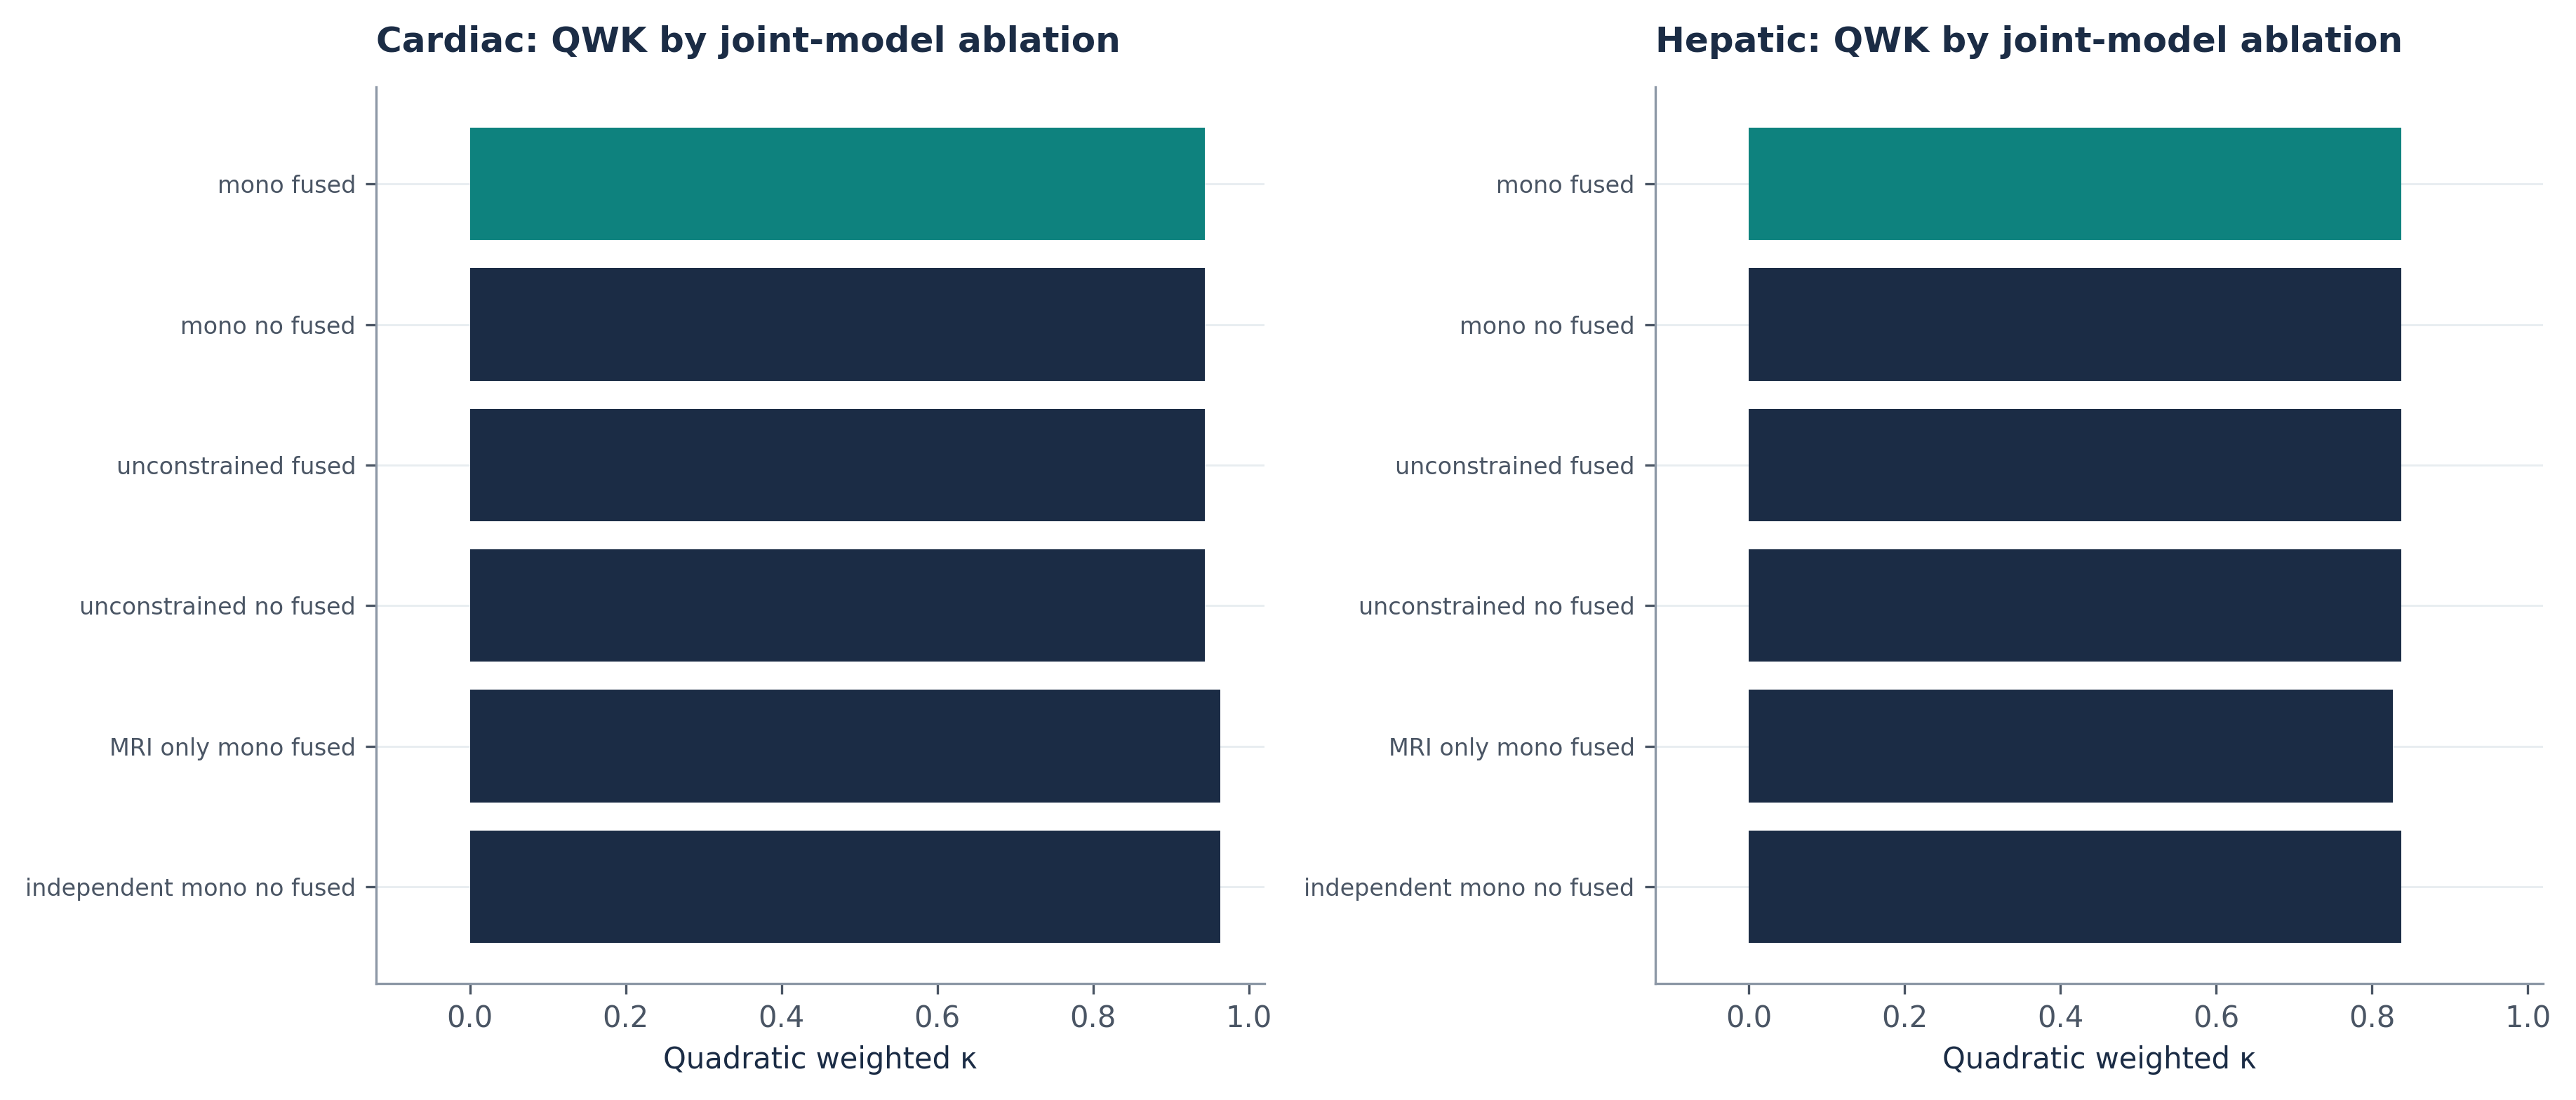

### J04_joint_ablations_RPS.png

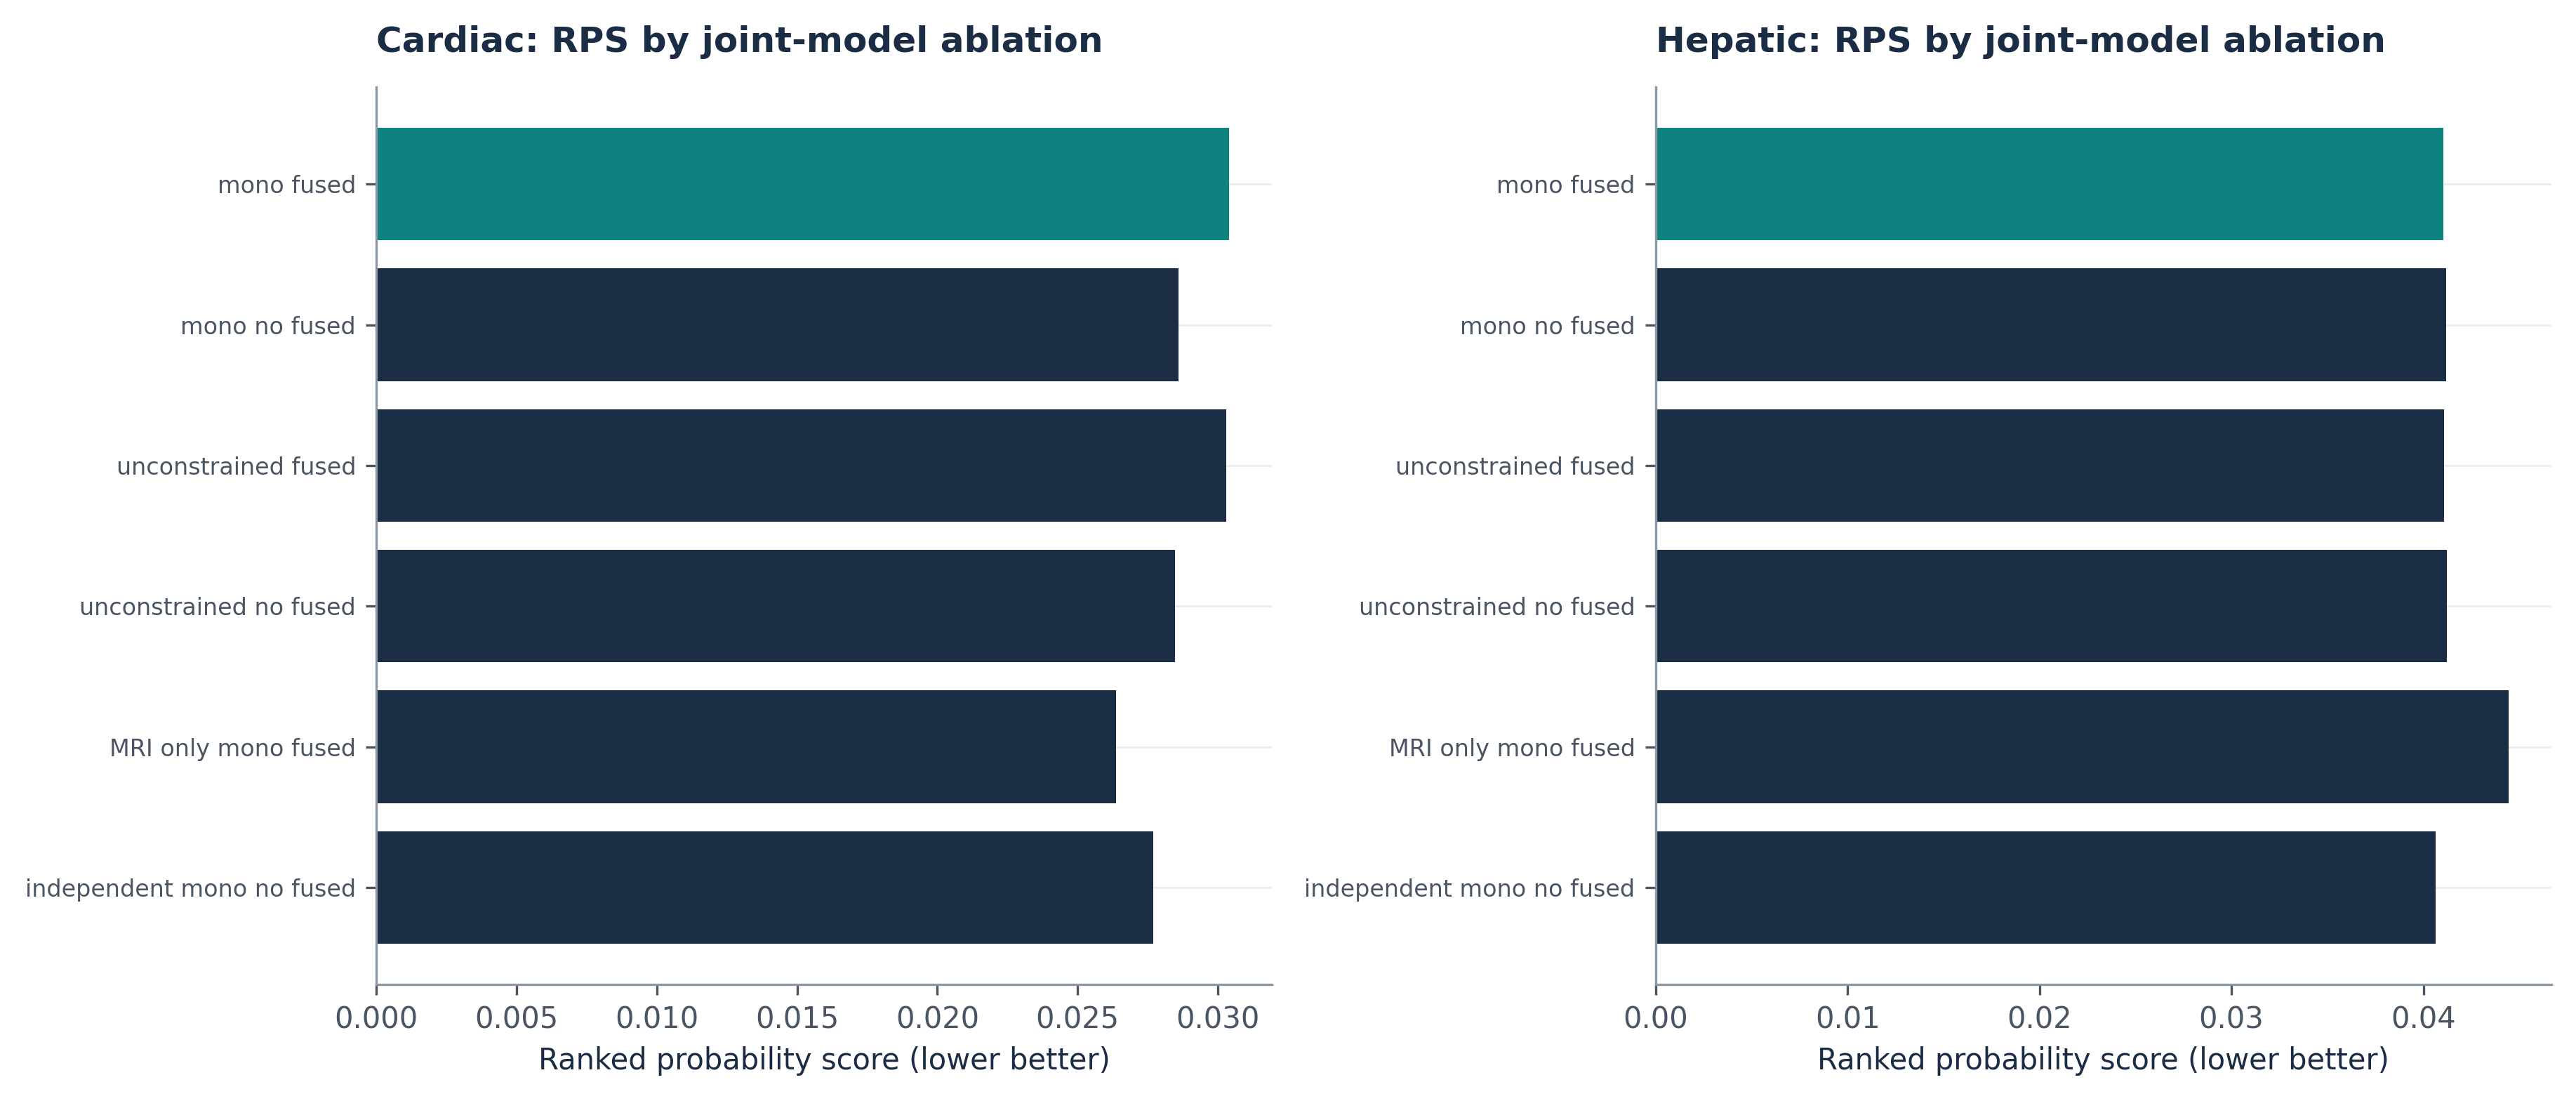

### J06_joint_and_marginal_conformal.png

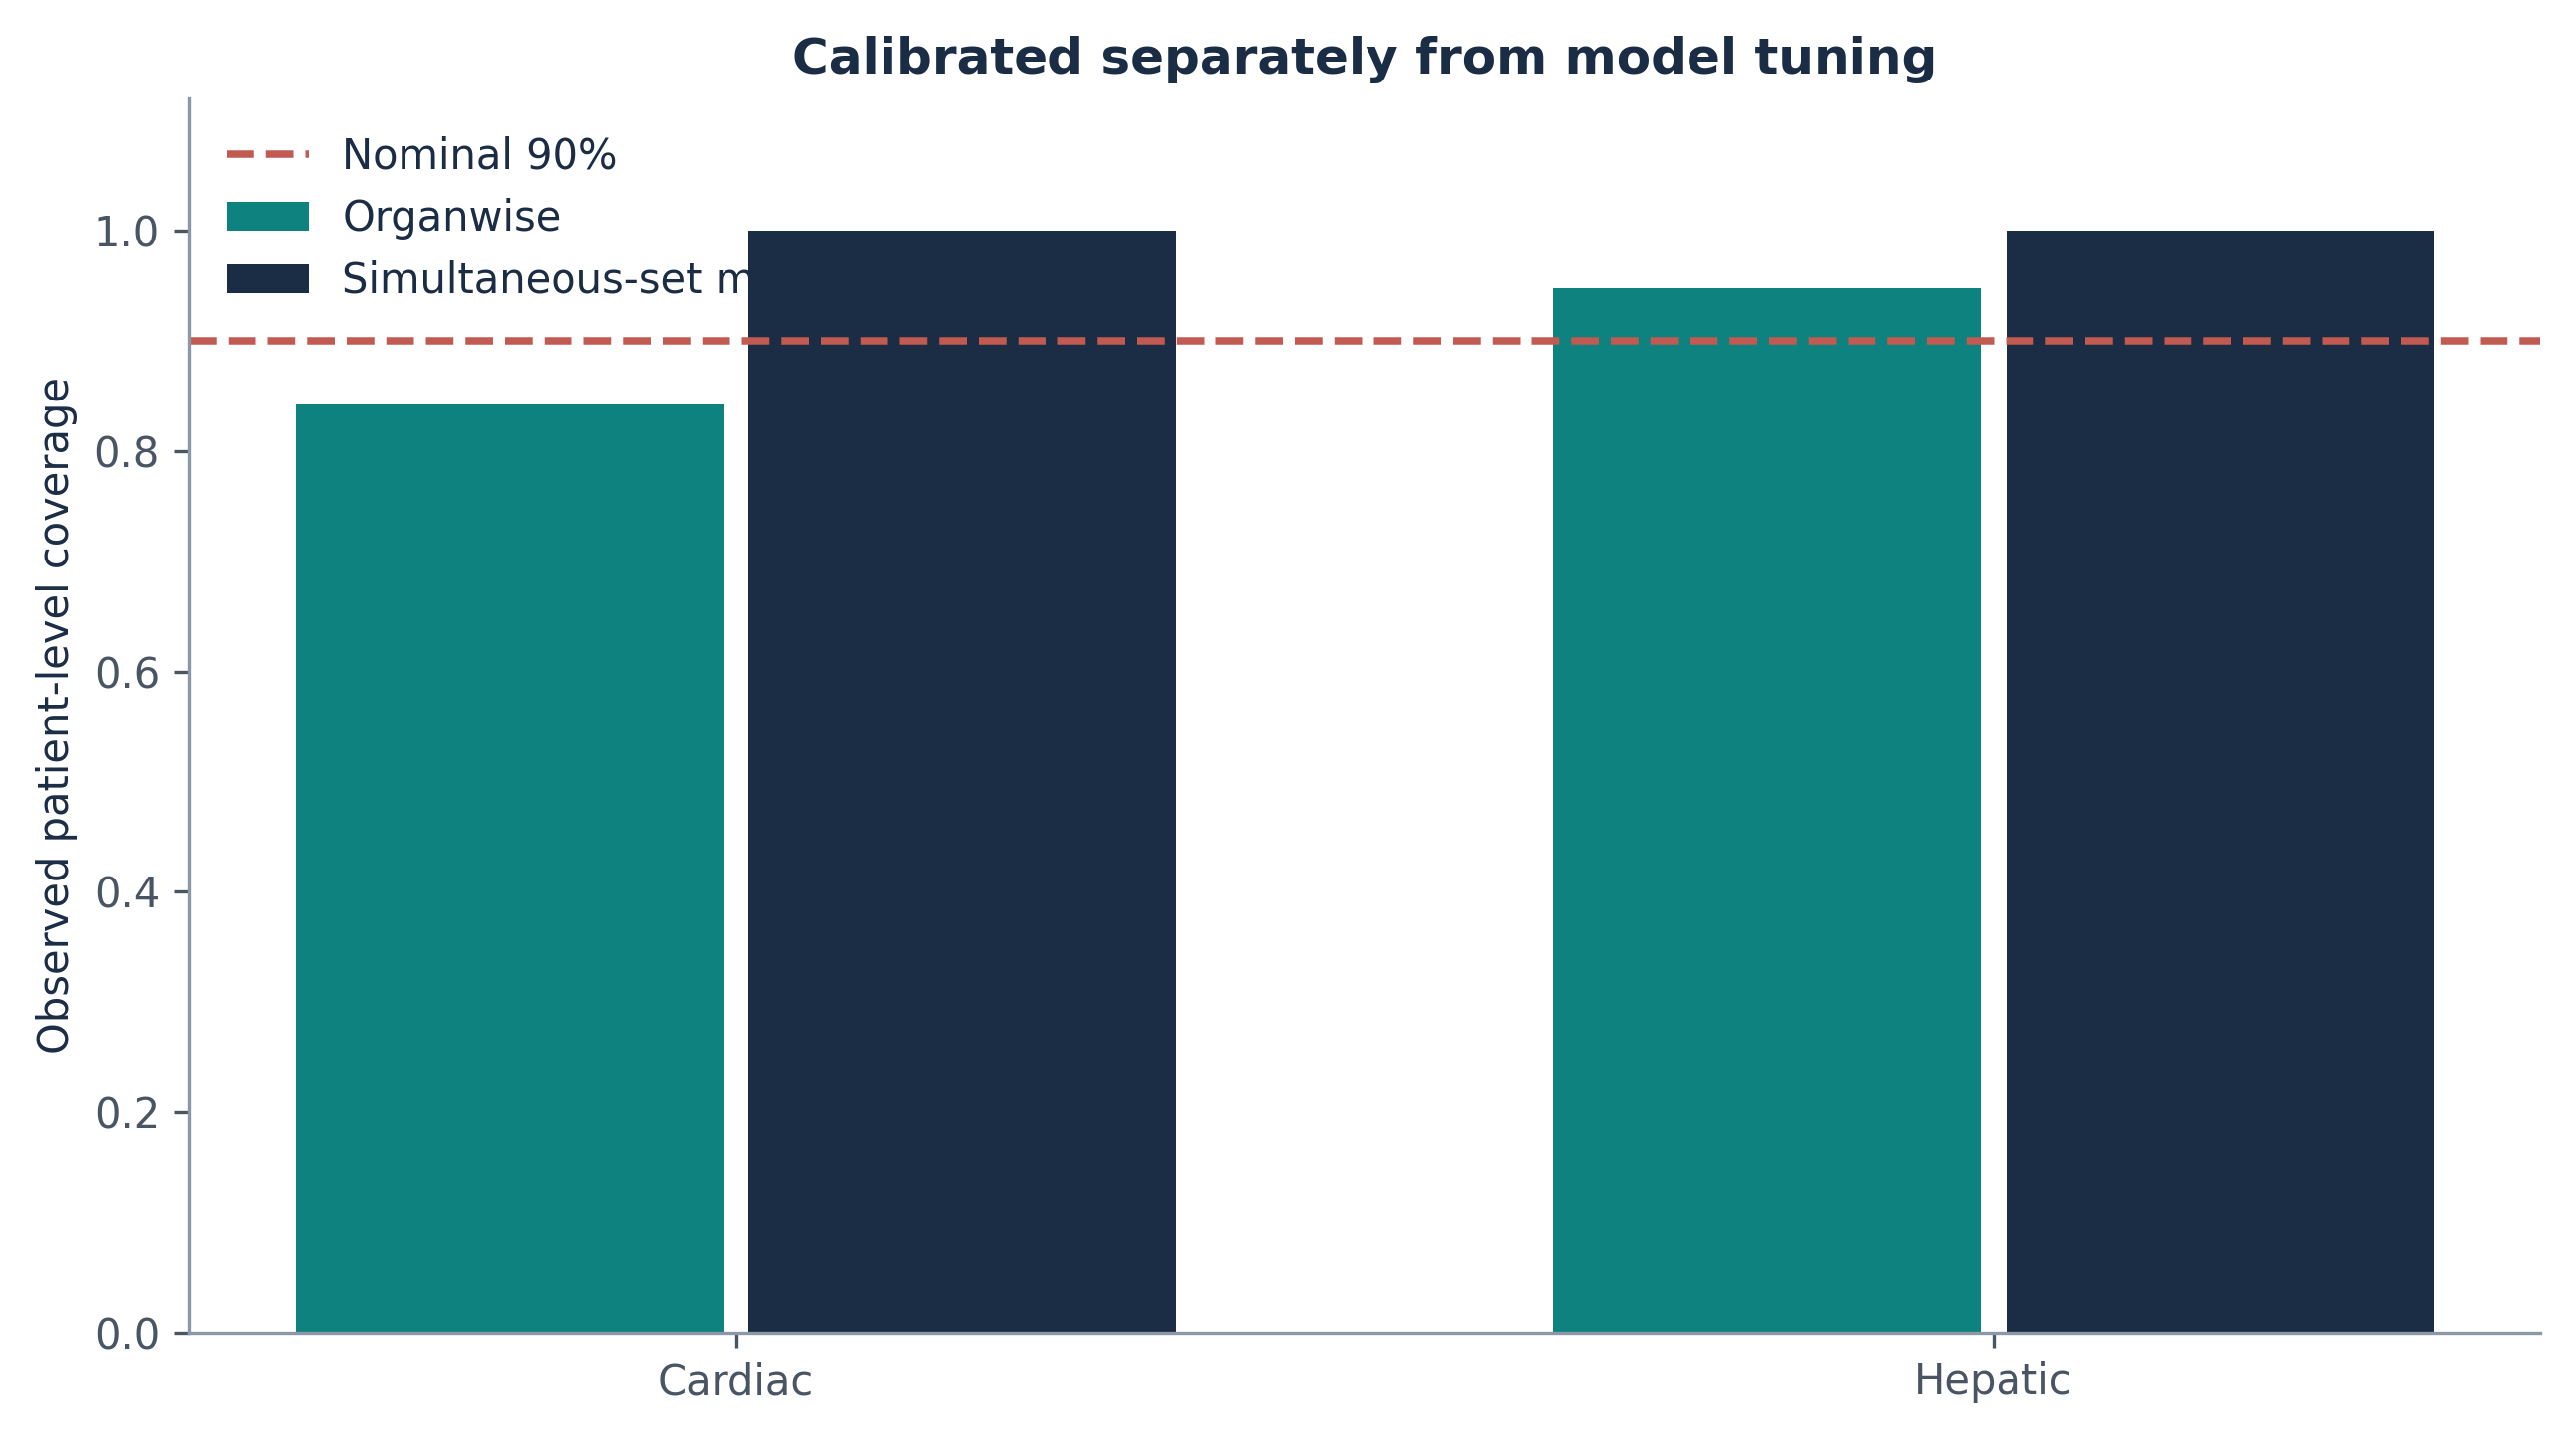

### J07_monotonicity_joint.png

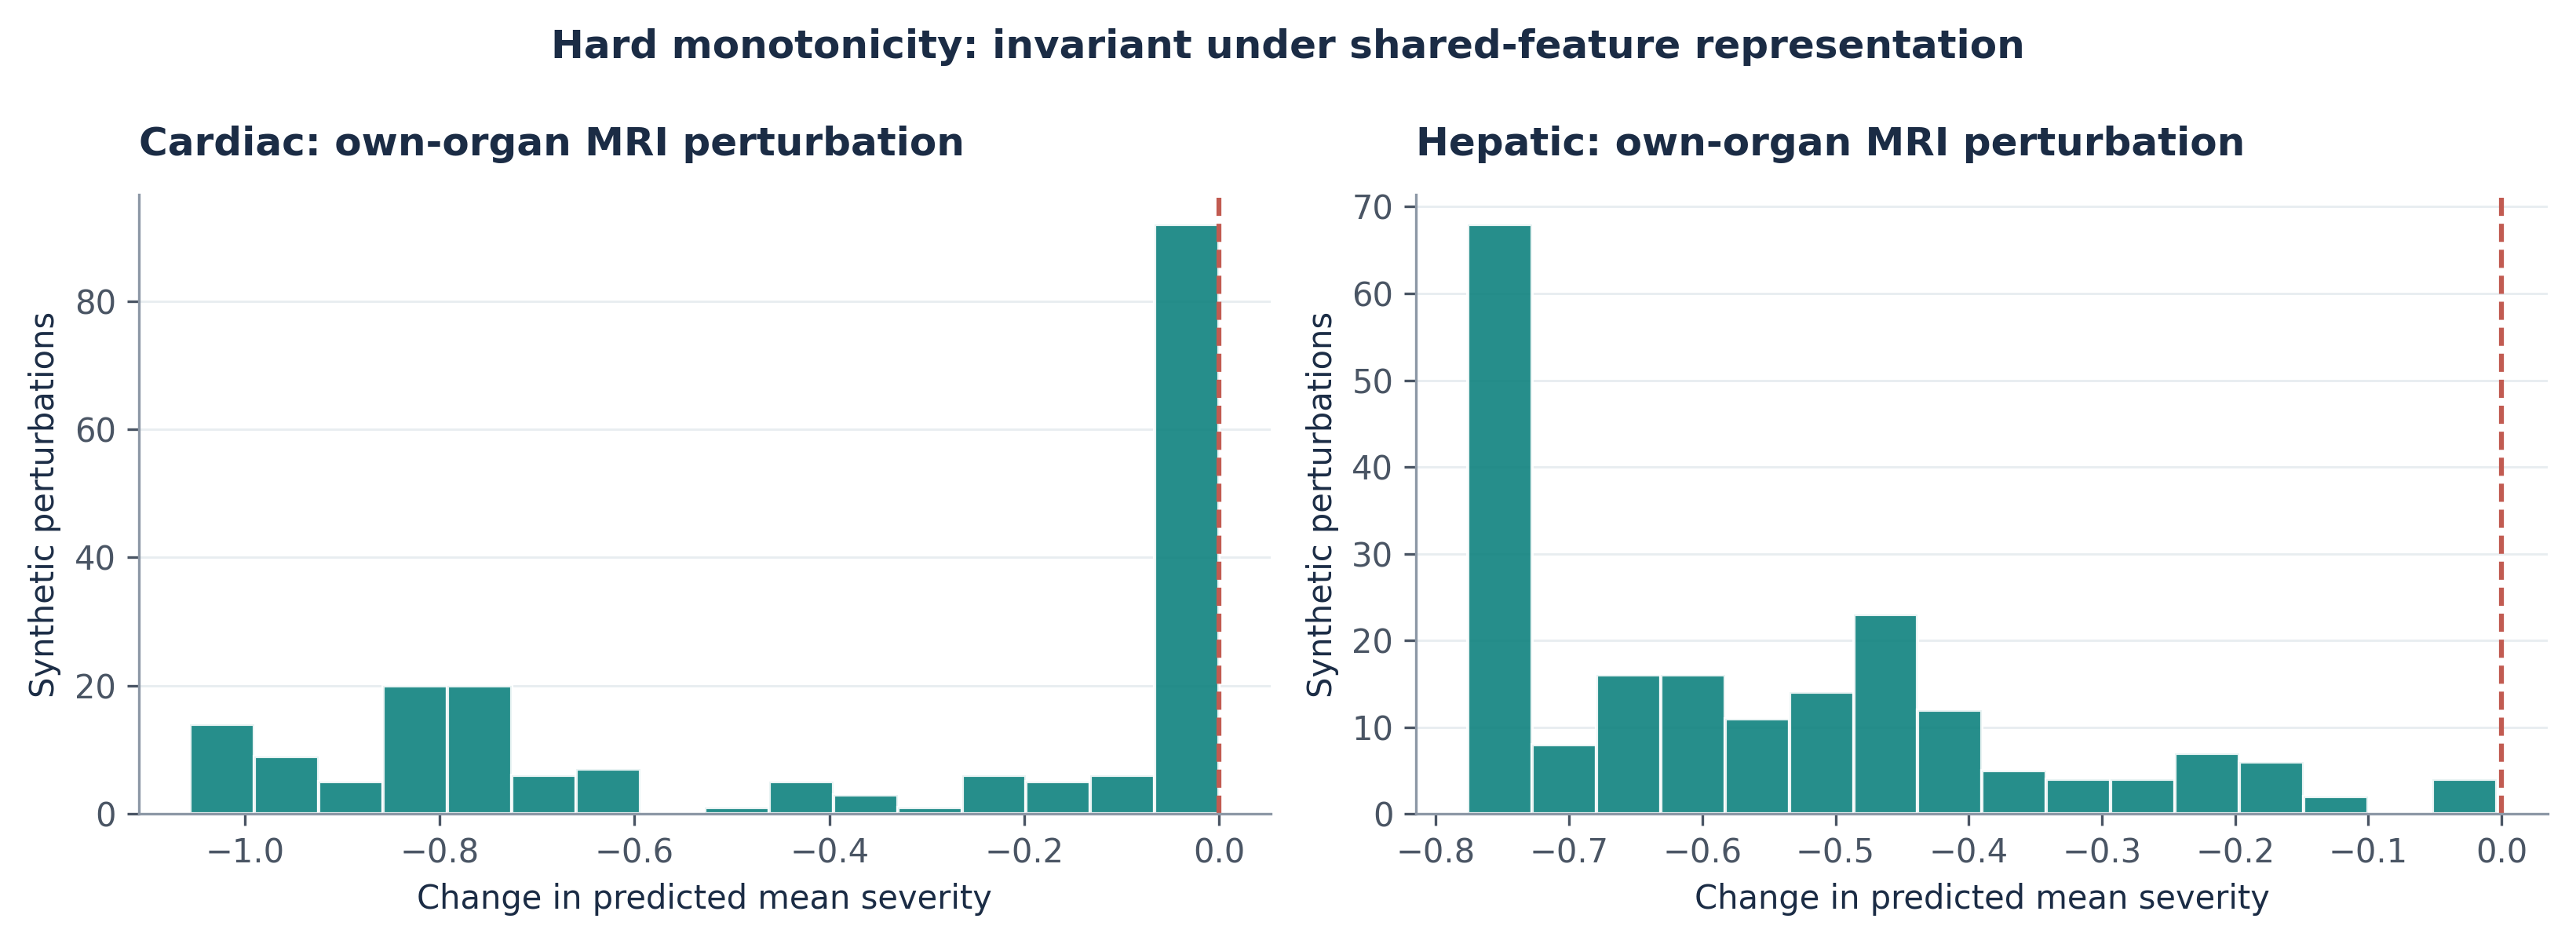

### J08_shared_embedding_coefficients.png

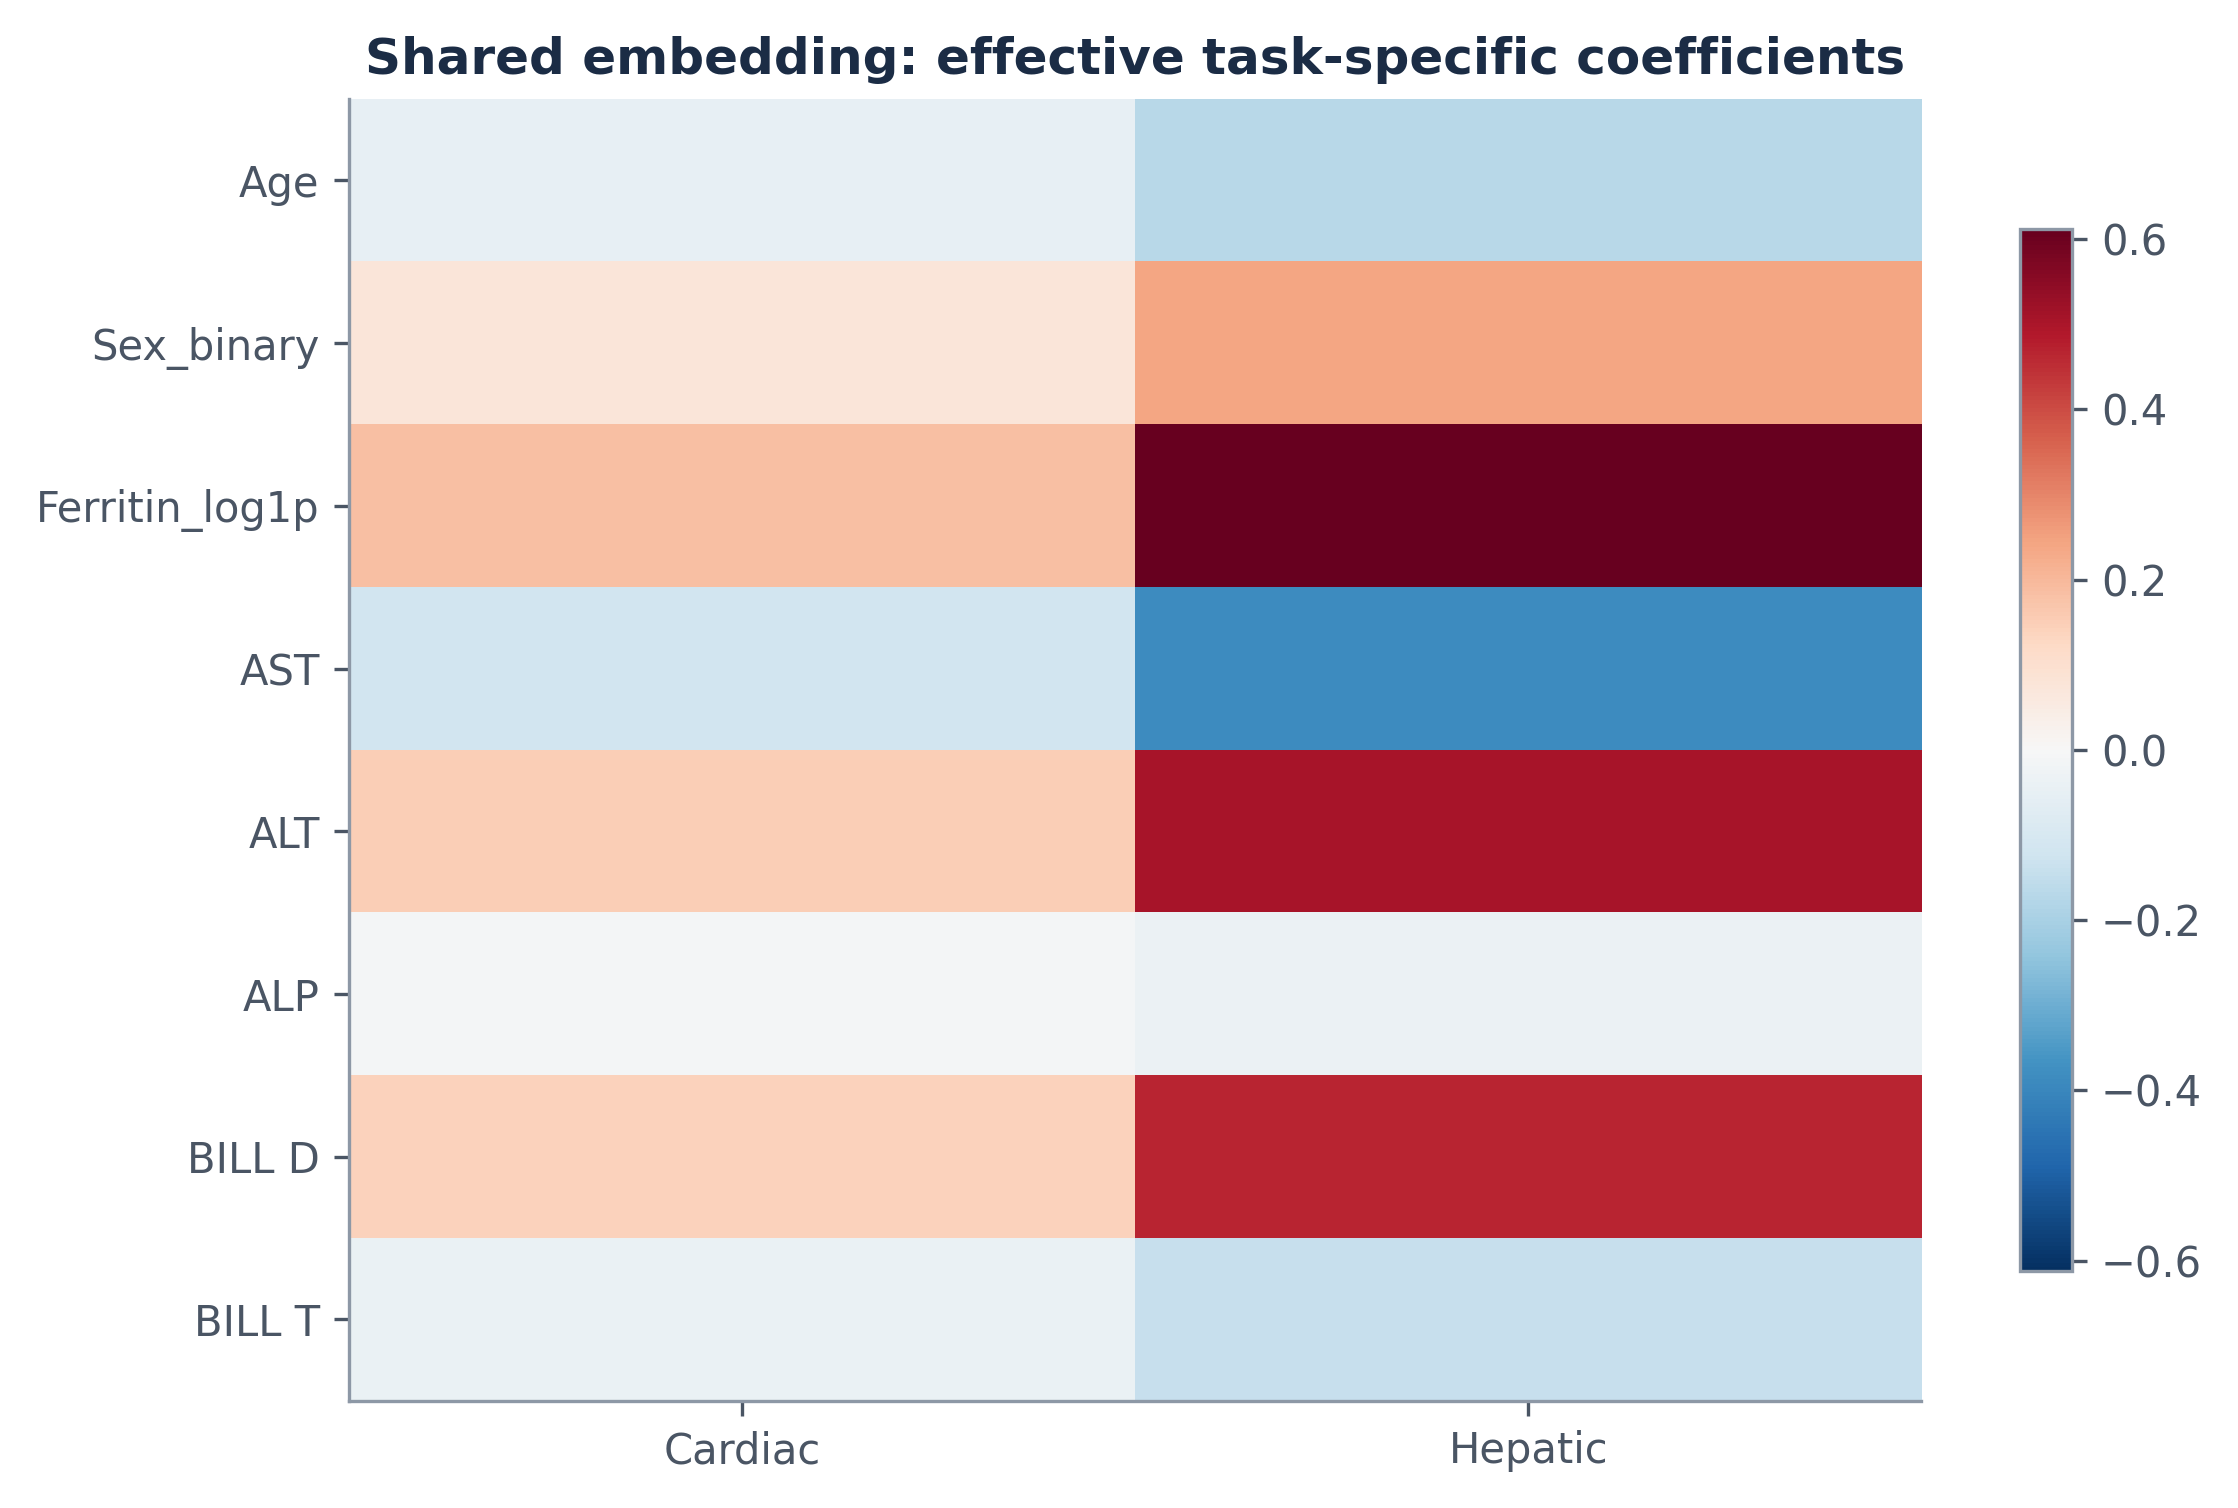

### J12_joint_vs_XGBoost_QWK.png

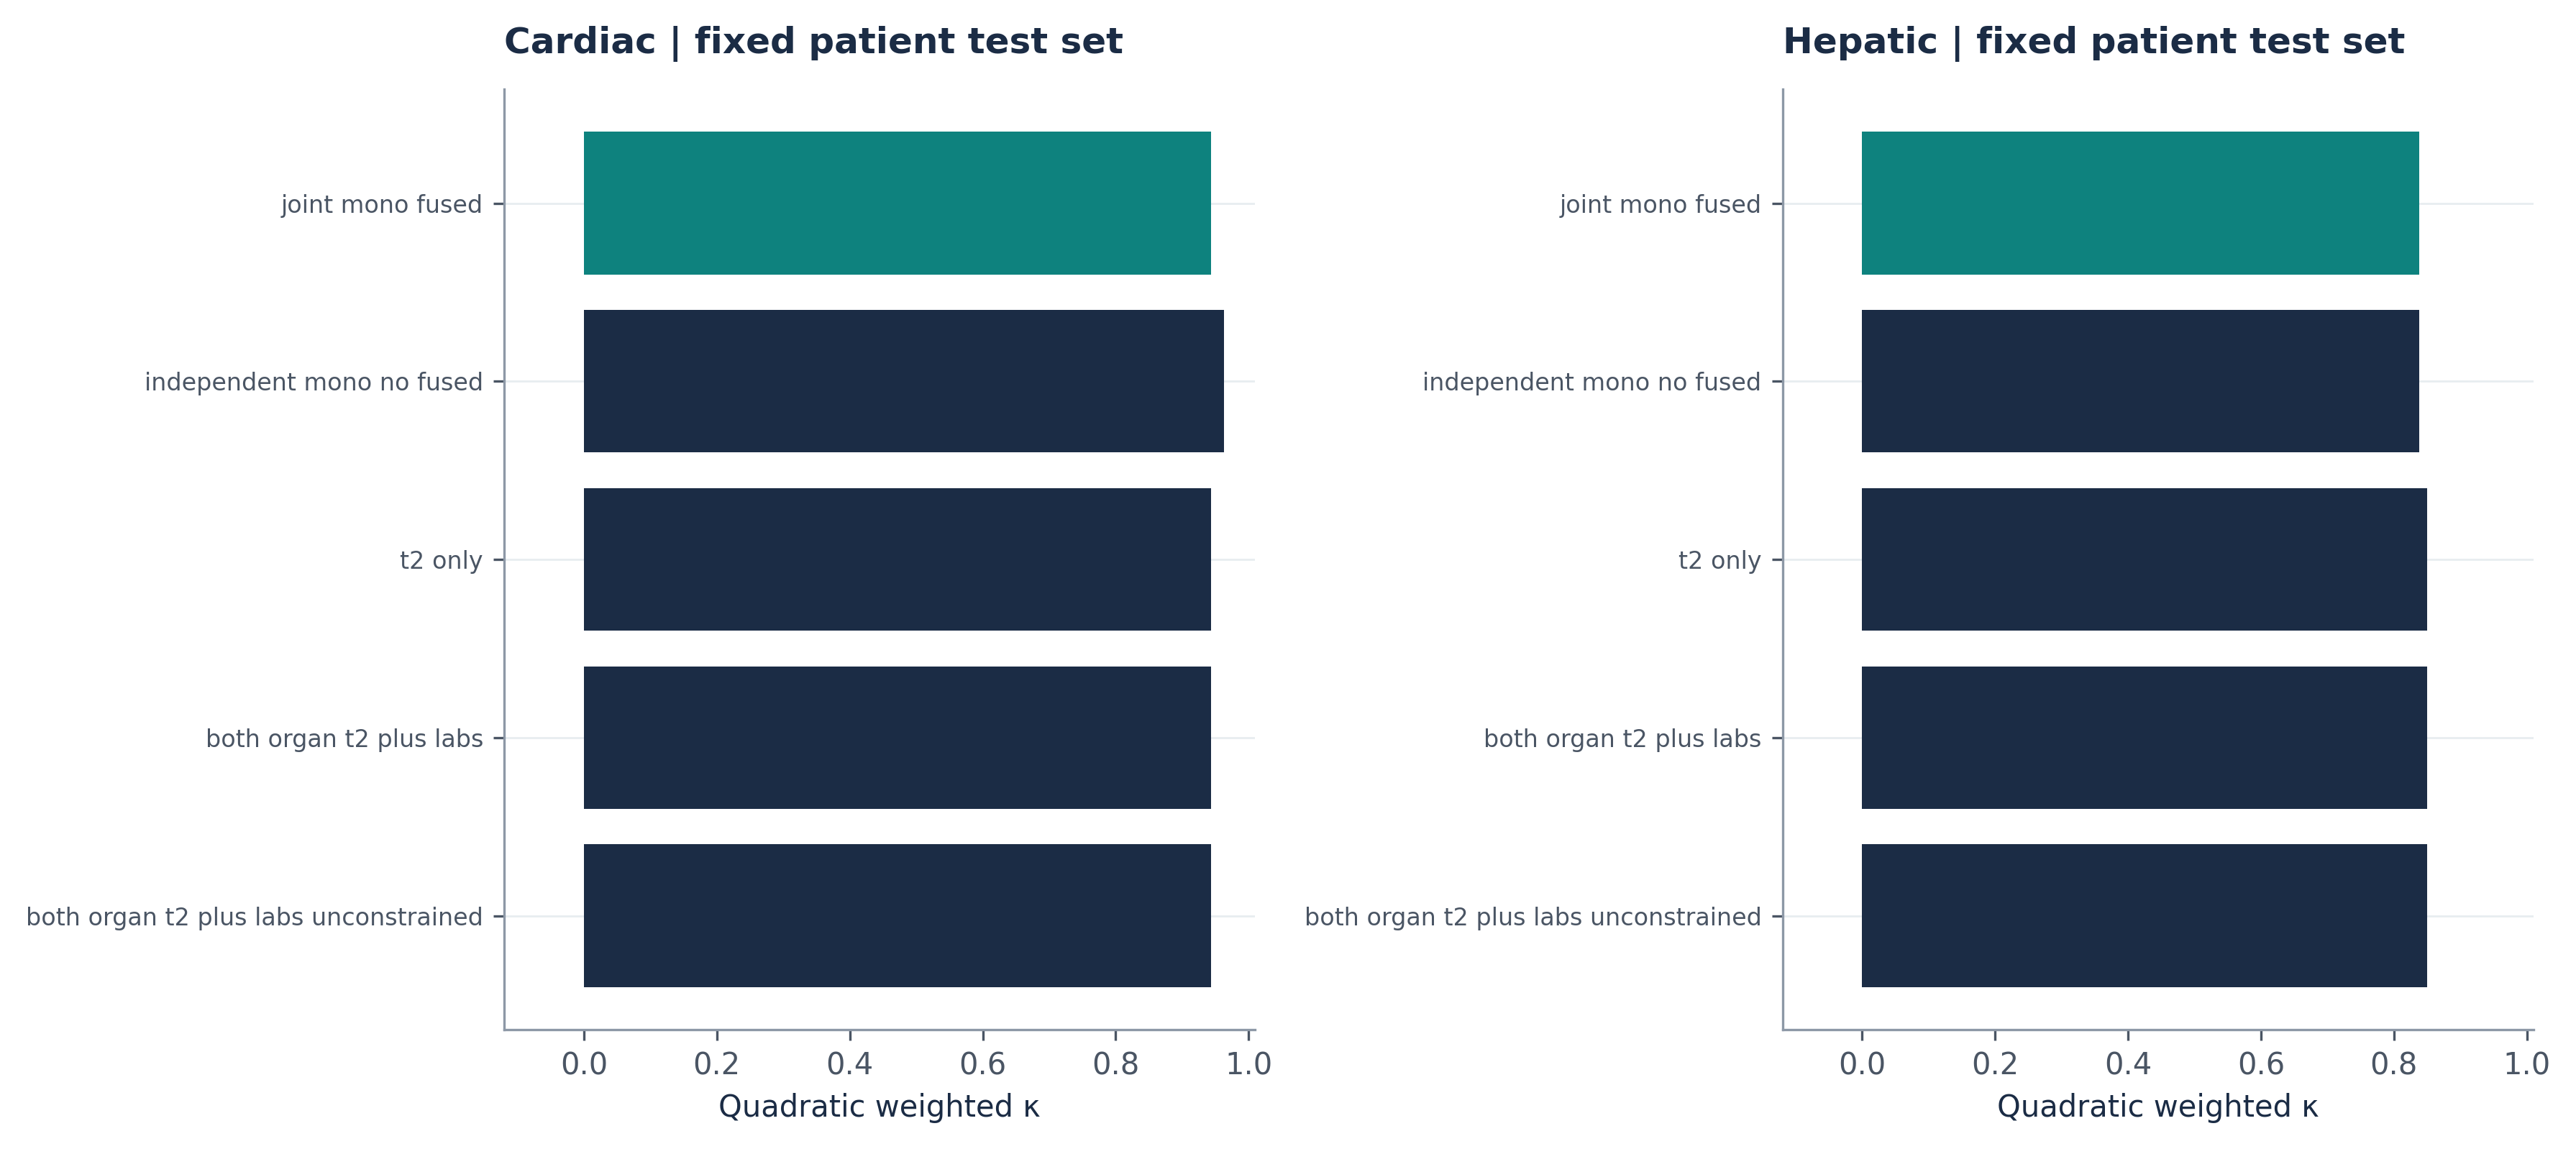

### F06_comparative_QWK.png

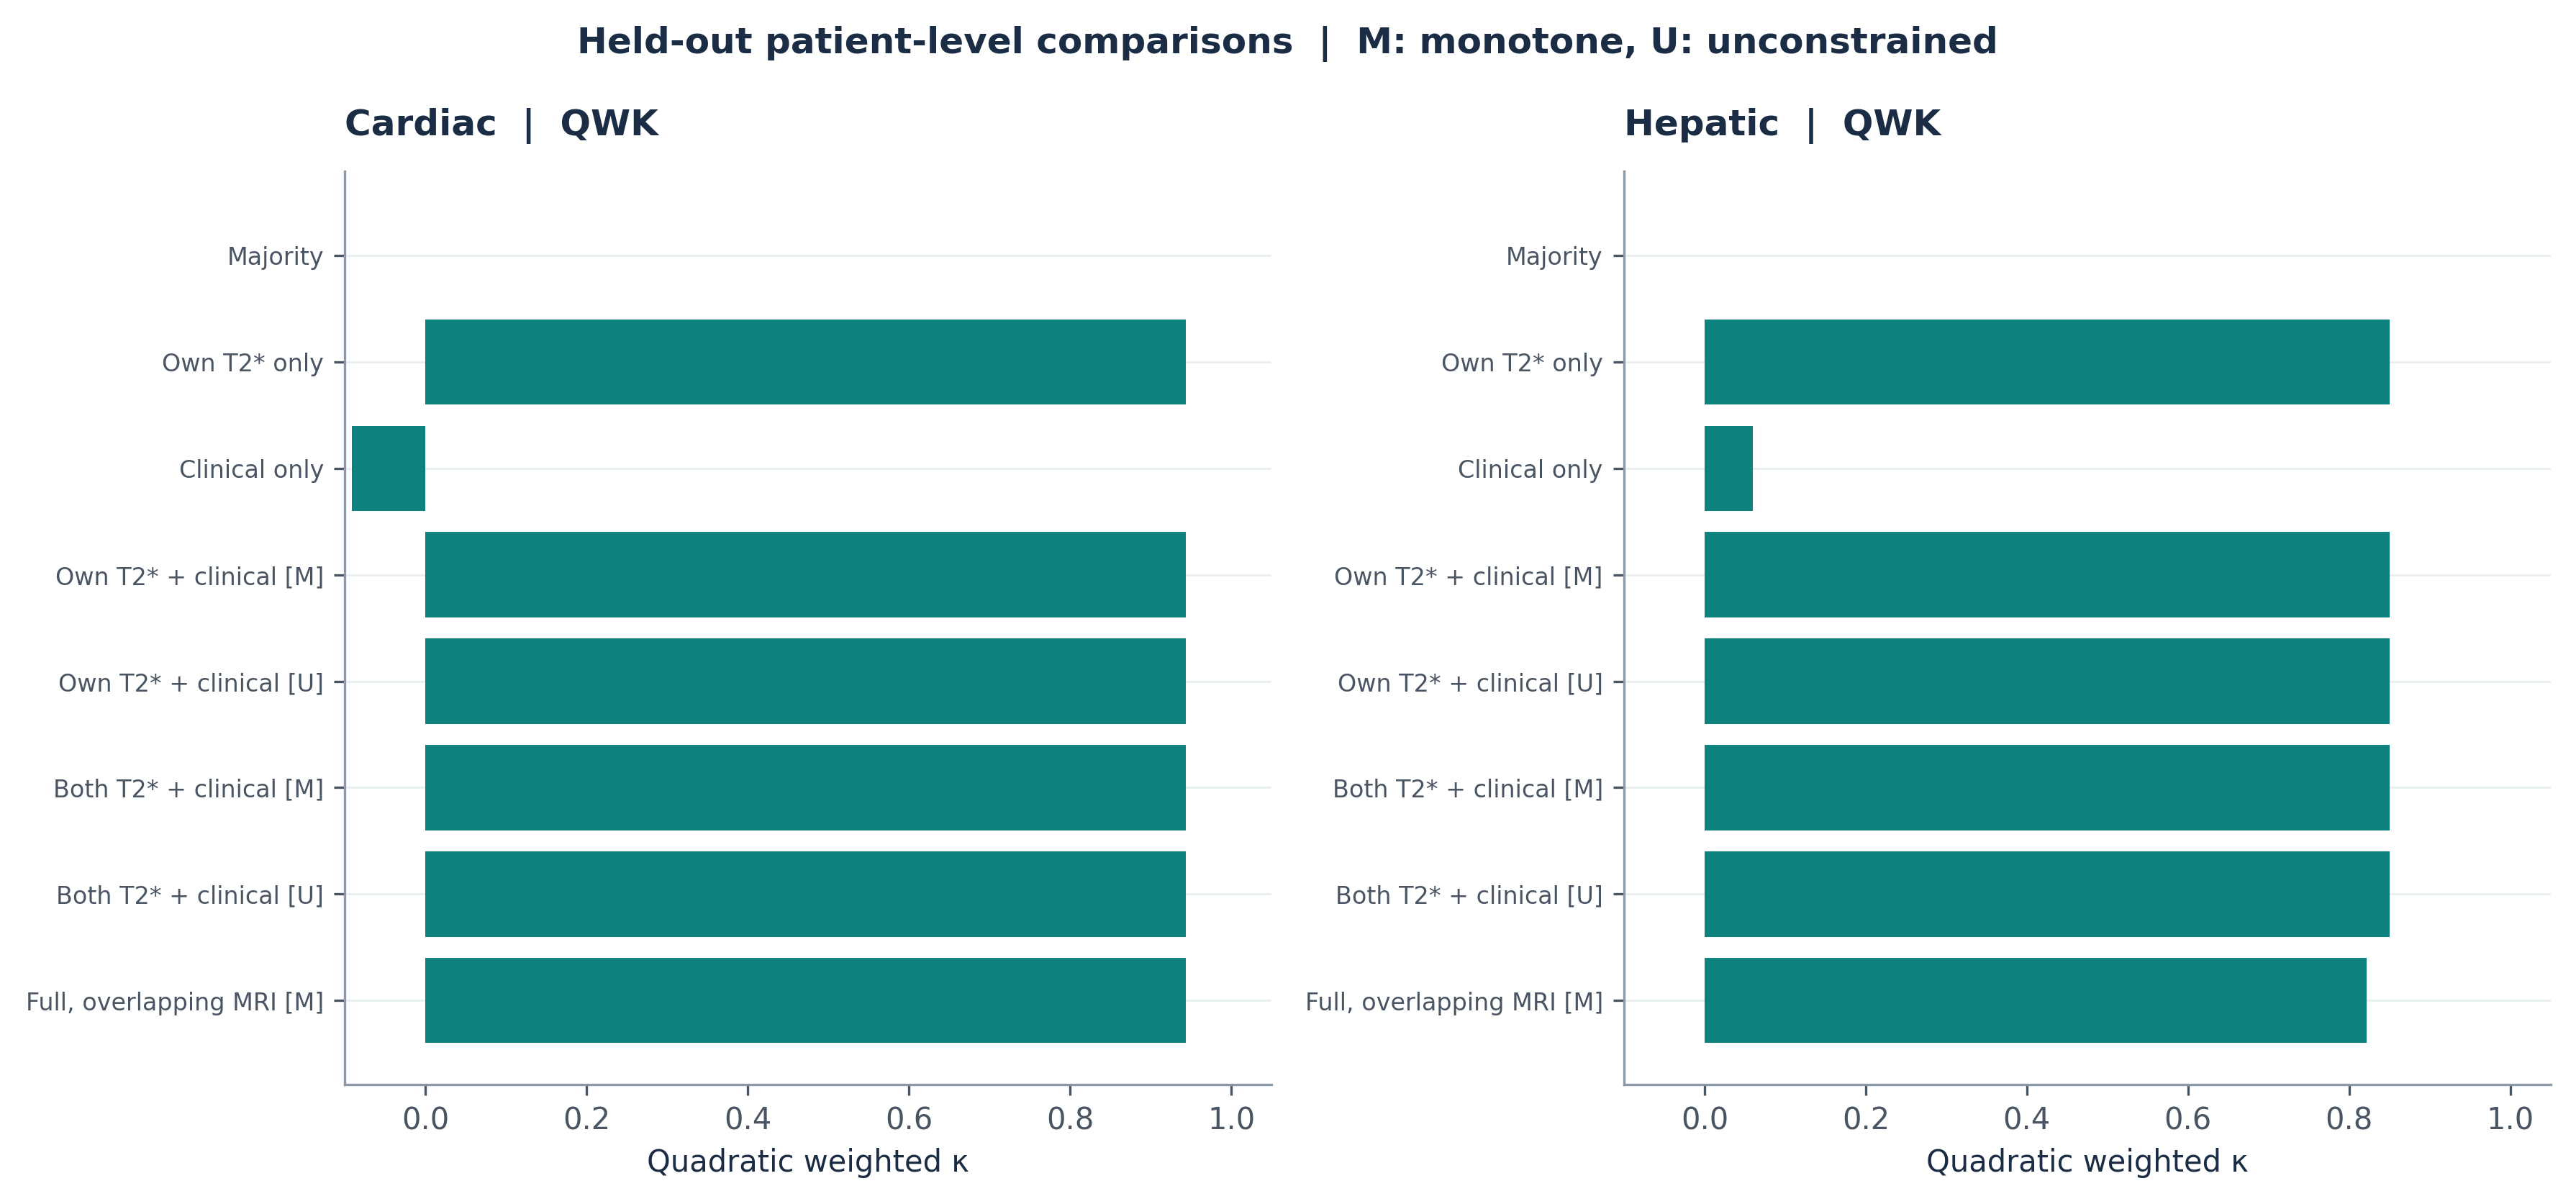

In [5]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown
out = Path('CHMMOT_Joint_Methodology_Results')
for fname in ['J03_joint_and_ablation_test_performance.csv',
              'J04_paired_joint_model_ablations.csv',
              'J06_split_conformal_joint_and_marginal.csv',
              'J07_monotonicity_analytic_and_numerical.csv',
              'J14_patient_bootstrap_joint_metrics.csv',
              'J15_primary_joint_vs_XGBoost_comparison.csv']:
    fp = out / 'tables' / fname
    if fp.exists():
        display(Markdown('### '+fname))
        display(pd.read_csv(fp).round(4))
for fig in ['J03_joint_ablations_QWK.png',
            'J04_joint_ablations_RPS.png',
            'J06_joint_and_marginal_conformal.png',
            'J07_monotonicity_joint.png',
            'J08_shared_embedding_coefficients.png',
            'J12_joint_vs_XGBoost_QWK.png',
            'F06_comparative_QWK.png']:
    fp=out/'figures'/fig
    if fp.exists():
        display(Markdown('### '+fig))
        display(Image(filename=str(fp),width=850))